# Avrupa Havalimanlarında Uçuş Trafiği Analizi

**Ders:** VBM661-Veri Görselleştirilmesi

**Öğrenci:** Melike Gullanova

**Öğrenci No:** N23236239

**Veri Kaynağı:** TidyTuesday - Flights Dataset

                  https://github.com/rfordatascience/tidytuesday/blob/main/data/2022/2022-07-12/readme.md


**Video Linki:** https://drive.google.com/drive/folders/1YgSei-46N27N-P-hYhX55wmIVHOtzBsK?usp=drive_link

> **Revizyon notu (Kasım 2026):** Veri setinin resmi değişken sözlüğüne göre `FLT_TOT_1` ve `FLT_TOT_IFR_2` sütunlarının **ikisi de IFR uçuş hareketi sayısıdır**; ilki EUROCONTROL Network Manager (NM), ikincisi havalimanı işletmecisi (APT) kaynağından gelir. İlk sürümde "IFR oranı" olarak yorumlanan `FLT_TOT_IFR_2 / FLT_TOT_1` metriği bu nedenle **"kaynak uyum oranı (APT / NM)"** olarak yeniden adlandırılmış ve ilgili yorumlar düzeltilmiştir. Ayrıca zaman serisi ayrıştırma grafiği bileşen başına ayrı panellere bölünmüş ve mevsimsellik matrisinde her yılın ayrı satırda gösterilmesi sağlanmıştır.


# Giriş

Bu çalışma, Avrupa’daki havalimanlarına ait aylık uçuş trafiği verileri kullanılarak, hava trafiğinin zaman ve mekân boyutlarında nasıl bir yapı sergilediğini incelemeyi amaçlamaktadır. Hava taşımacılığı sistemleri, hem talep dalgalanmalarına hem de coğrafi yoğunlaşmalara son derece duyarlı karmaşık yapılardır. Bu nedenle uçuş trafiğinin yalnızca toplam büyüklüğü değil, zaman içinde nasıl değiştiği ve mekânsal olarak nasıl dağıldığı da sistemin işleyişini anlamak açısından kritik öneme sahiptir.

Çalışmada ele alınan temel problem, Avrupa hava trafiğinin belirli dönemlerde ve belirli merkezlerde yoğunlaşıp yoğunlaşmadığını, başka bir ifadeyle sistemin mevsimsel ritimler ve merkez-çevre (hub-spoke) yapısı gösterip göstermediğini ortaya koymaktır. Özellikle büyük havalimanlarının, toplam uçuş hacmi ve veri raporlama özellikleri (EUROCONTROL Network Manager ile havalimanı işletmecisi kayıtlarının birbirini ne ölçüde tuttuğu) bakımından sistem içinde nasıl bir rol üstlendiği bu problem çerçevesinde değerlendirilmiştir.

Temel Kavramlar

Modern sivil havacılık sistemleri büyük ölçüde hub-and-spoke (merkez ve kollar) mimarisiyle çalışır.

*   Hub (merkez havalimanı)
Çok sayıda uçuşun toplandığı, aktarmaların yapıldığı, uçuş ağının düğüm noktaları olan büyük havalimanlarıdır.
*   Spoke (kol havalimanı)
Daha küçük, genellikle doğrudan hub’a bağlı olan ve trafiğin oradan dağıtıldığı havalimanlarıdır.

IFR (Instrument Flight Rules - Aletli Uçuş Kuralları)

*   IFR, uçakların görsel referanslara değil, uçuş aletlerine ve hava trafik kontrol talimatlarına dayanarak uçtuğu operasyon türünü ifade eder. **Bu veri setindeki tüm uçuş sayıları IFR hareketleridir;** VFR uçuşları veri setinde yer almaz.

VFR (Visual Flight Rules - Görerek Uçuş Kuralları)

*   Pilotun uçağı doğrudan dış görüşe bakarak yönettiği uçuş kuralıdır. Navigasyon, ayrım ve konum bilgisi esas olarak pilotun gözlemleri ile sağlanır.
VFR uçuşları genellikle iyi hava koşullarında, görüş mesafesinin yüksek olduğu durumlarda ve küçük ve orta ölçekli havalimanlarında yapılır.











## Veri Setinin Yüklenmesi ve İlk İnceleme

Bu çalışmada, Avrupa’daki havalimanlarına ait aylık uçuş trafiği bilgilerini içeren kapsamlı bir veri seti kullanılmıştır. Veri kaynağı olarak, açık veri platformu TidyTuesday kapsamında paylaşılan flights.csv dosyası tercih edilmiştir. Veri seti, 2016'dan 2022 yılına kadar olan uçuş verilerini kapsamakta ve havalimanı bazında aylık uçuş istatistikleri sunmaktadır.

Bu adımda analizde kullanılacak veri kümesi yüklenmiş ve görselleştirme ile veri inceleme sürecini kolaylaştıracak temel Python kütüphaneleri tanımlanmıştır.



In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose
import plotly.express as px
import plotly.graph_objects as go



URL = "https://raw.githubusercontent.com/rfordatascience/tidytuesday/refs/heads/main/data/2022/2022-07-12/flights.csv"
df = pd.read_csv(URL)

# Veri Yapısının İncelenmesi ve Ön İşleme Adımları

Bu aşamada, veri setinin yapısal özelliklerini anlamak ve analiz için uygun hâle getirmek amacıyla bir dizi ön inceleme ve ön işleme adımı uygulanmıştır.

Her bir değişkenin veri tipi görüntülenmiştir. Bu inceleme sayesinde, sayısal değişkenler (örneğin toplam uçuş sayıları) ile metinsel değişkenler (örneğin havalimanı adı, ülke bilgisi) net biçimde ayrıştırılmıştır. Özellikle havalimanı işletmecisi kaynağından gelen (`_IFR_2` uzantılı) değişkenlerin float türünde olması, bu sütunlarda eksik (NaN) değerler bulunduğuna işaret etmektedir.

Veri setinin genel yapısını daha iyi kavrayabilmek amacıyla, rastgele seçilmiş 5 gözlem df.sample() fonksiyonu kullanılarak görüntülenmiştir. Bu adım, verinin yalnızca ilk satırlarına bakmak yerine, farklı yıllar ve ülkelerden örneklerin görülmesini sağlayarak daha temsil edici bir ön izleme sunmaktadır.

## Ham Veri Durumu
Bu çalışmada kullanılan uçuş verisi, ilk olarak herhangi bir filtreleme veya temizlik işlemi uygulanmadan incelenmiştir. Bu adımın amacı, analiz öncesinde veri setinin genel büyüklüğünü, kapsamını ve çeşitliliğini anlamaktır.

Ham veri seviyesinde toplam kayıt sayısı, benzersiz havalimanı sayısı ve veri kayıtlarının zaman aralığı çıktısı elde edilmiştir.

## Zaman Boyutunun Düzenlenmesi

Zamansal analizlerin sağlıklı biçimde gerçekleştirilebilmesi için, FLT_DATE sütunu tarih formatına dönüştürülmüştür. Bu dönüşüm sırasında, hatalı veya geçersiz tarih değerlerinin analiz sürecini bozmasını önlemek amacıyla errors="coerce" parametresi kullanılmıştır. Bu sayede, geçersiz tarih değerleri otomatik olarak eksik değer (NaT) olarak işaretlenmiştir.

Buna ek olarak:

*   year değişkeni, yıl bilgisini doğrudan temsil edecek şekilde oluşturulmuş,
*   month değişkeni, ay bilgisinin sayısal karşılığını içerecek biçimde tanımlanmış,
*   ym değişkeni ise yıl-ay (örneğin 2021-07) düzeyinde bir zaman temsili sağlayacak şekilde türetilmiştir.


Bu yeni değişkenler, ilerleyen aşamalarda yapılacak aylık karşılaştırmalar ve zamansal gruplaştırmalar için analizi kolaylaştıran bir yapı sunmaktadır.

## Mekânsal Bilgilerin Standartlaştırılması

Mekânsal analizlerde tutarlılığı sağlamak amacıyla, havalimanı ve ülke bilgileri metinsel olarak temizlenmiştir. Bu kapsamda:

*   APT_ICAO sütunu string formata dönüştürülmüş ve olası baştaki veya sondaki boşluklar temizlenmiştir.

*   STATE_NAME sütunu kullanılarak, ülke bilgisi country adlı yeni bir değişken altında standartlaştırılmıştır.

Bu adım, aynı havalimanı veya ülkenin farklı yazım biçimlerinden kaynaklanabilecek tutarsızlıkların önüne geçmek için uygulanmıştır.

## Operasyonel Değişkenlerin Kontrolü

Analizde kullanılacak temel operasyonel değişkenler (toplam kalkış, toplam varış, toplam uçuş ve havalimanı işletmecisi kaynaklı uçuş sayıları) bir liste altında tanımlanmış ve bu değişkenlerin veri setinde eksiksiz olarak bulunup bulunmadığı kontrol edilmiştir.

Gerçekleştirilen kontrol sonucunda, analizde ihtiyaç duyulan tüm metriklerin veri setinde mevcut olduğu görülmüş ve eksik metrik sütunu bulunmadığı tespit edilmiştir. Bu durum, veri setinin operasyonel açıdan bütünlüklü olduğunu göstermektedir.

In [3]:
import pandas as pd

pd.set_option("display.max_colwidth", None)
pd.set_option("display.expand_frame_repr", False)
pd.set_option("display.width", 0)

summary_table = pd.DataFrame({
    "Özellik": [
        "Toplam kayıt (satır)",
        "Toplam değişken (sütun)",
        "Benzersiz havalimanı",
        "Zaman aralığı (ilk tarih)",
        "Zaman aralığı (son tarih)"
    ],
    "Değer": [
        df.shape[0],
        df.shape[1],
        df["APT_ICAO"].nunique(),
        pd.to_datetime(df["FLT_DATE"], errors="coerce").min().date(),
        pd.to_datetime(df["FLT_DATE"], errors="coerce").max().date()
    ]
})

display(summary_table)

# Rastgele 5 örnek gözlem (verinin nasıl göründüğünü göstermek için)
sample_table = df.sample(5, random_state=42)

display(sample_table)


,Özellik,Değer
0,Toplam kayıt (satır),688099
1,Toplam değişken (sütun),14
2,Benzersiz havalimanı,332
3,Zaman aralığı (ilk tarih),2016-01-01
4,Zaman aralığı (son tarih),2022-05-31


,YEAR,MONTH_NUM,MONTH_MON,FLT_DATE,APT_ICAO,APT_NAME,STATE_NAME,FLT_DEP_1,FLT_ARR_1,FLT_TOT_1,FLT_DEP_IFR_2,FLT_ARR_IFR_2,FLT_TOT_IFR_2,Pivot Label
584564,2021,7,JUL,2021-07-05T00:00:00Z,LFJR,Angers-Marcé,France,3,3,6,NaN,NaN,NaN,Angers-Marcé (LFJR)
199467,2018,1,JAN,2018-01-21T00:00:00Z,LFLY,Lyon-Bron,France,7,5,12,NaN,NaN,NaN,Lyon-Bron (LFLY)
89560,2016,12,DEC,2016-12-04T00:00:00Z,LGIR,Heraklion,Greece,20,17,37,NaN,NaN,NaN,Heraklion (LGIR)
345707,2019,5,MAY,2019-05-06T00:00:00Z,EPLB,Lublin,Poland,4,4,8,NaN,NaN,NaN,Lublin (EPLB)
135742,2017,5,MAY,2017-05-29T00:00:00Z,LFLS,Grenoble-Isère,France,8,6,14,NaN,NaN,NaN,Grenoble-Isère (LFLS)


# Değişken Sözlüğünün Oluşturulması

Bu aşamada, veri setinde yer alan tüm değişkenlerin yapısını, anlamını ve analizdeki rollerini açık biçimde ortaya koymak amacıyla bir veri kataloğu (data catalog) oluşturulmuştur. Veri kataloğu, her bir sütunun hem teknik özelliklerini hem de analitik bağlamdaki işlevini sistematik biçimde belgelemeyi amaçlamaktadır.

Oluşturulan veri kataloğunda, değişkenler içeriklerine göre anlamlı kategoriler altında sınıflandırılmıştır:

### Zamansal Değişkenler

Bu grup, uçuşların hangi yıl ve aya ait olduğunu tanımlar ve zaman serisi analizlerinin temelini oluşturur.

YEAR: Gözlemin ait olduğu takvim yılıdır.

MONTH_NUM: Ay bilgisinin sayısal karşılığıdır (1–12).

MONTH_MON: Ayın metinsel etiketi (JAN, FEB, vb.).

FLT_DATE: İlgili ayın başlangıç tarihini temsil eden zaman damgasıdır.

Bu değişkenler sayesinde uçuş trafiğinin uzun dönemli eğilimleri, mevsimsellik yapısı ve zaman içindeki dalgalanmaları analiz edilebilmektedir.

### Mekânsal Değişkenler

Bu grup, uçuşların nerede gerçekleştiğini tanımlar.


*   APT_ICAO: Havalimanının 4 harfli uluslararası ICAO kodu.
*   APT_NAME: Havalimanının adı.
*   STATE_NAME: Havalimanının bulunduğu ülke.

Bu değişkenler sayesinde havalimanları arasında coğrafi karşılaştırmalar, ülke bazlı yoğunluklar ve bölgesel farklılıklar incelenebilir.

### Operasyonel Değişkenler

Bu değişkenler, bir havalimanında ilgili ayda gerçekleşen uçuş hacmini sayısal olarak ifade eder.

*   FLT_DEP_1: Aylık IFR kalkış sayısı (kaynak: EUROCONTROL Network Manager)
*   FLT_ARR_1: Aylık IFR varış sayısı (kaynak: Network Manager)
*   FLT_TOT_1: Aylık toplam IFR uçuş hareketi (kalkış + varış, kaynak: Network Manager)

Bu grup, havalimanlarının operasyonel büyüklüğünü ve trafik yoğunluğunu ölçmek için kullanılır.

### Havalimanı İşletmecisi Kaynaklı Değişkenler

Veri setinin değişken sözlüğüne göre bu sütunlar da IFR uçuş hareketlerini sayar; fark, verinin **havalimanı işletmecisi** tarafından raporlanmasıdır. Yani aynı büyüklüğün ikinci bir kaynaktan ölçümüdür.


*   FLT_DEP_IFR_2: IFR kalkış sayısı (kaynak: havalimanı işletmecisi)
*   FLT_ARR_IFR_2: IFR varış sayısı (kaynak: havalimanı işletmecisi)
*   FLT_TOT_IFR_2: Toplam IFR uçuş hareketi (kaynak: havalimanı işletmecisi)

Bu değişkenler sayesinde iki bağımsız kaynağın aynı havalimanı ve ay için ne ölçüde tutarlı olduğu (veri kalitesi) incelenebilir.

### Etiket ve Türetilmiş Değişkenler


*   Pivot Label: Havalimanı adı ile ICAO kodunu birlikte gösteren görsel etiket (örneğin Antwerp (EBAW)).
*   year, month, ym, icao, country: Analiz ve gruplanma işlemlerini kolaylaştırmak için veri setinden türetilmiş yardımcı değişkenlerdir.






In [4]:
catalog = pd.DataFrame({
    "column": df.columns,
    "dtype": [str(t) for t in df.dtypes],
    "example": [df[c].dropna().iloc[0] if df[c].notna().any() else None for c in df.columns],
    "role": [
        "Zaman (yıl)" if c=="YEAR" else
        "Zaman (ay num)" if c=="MONTH_NUM" else
        "Zaman (ay etiketi)" if c=="MONTH_MON" else
        "Zaman (tarih)" if c=="FLT_DATE" else
        "Mekân (ICAO)" if c=="APT_ICAO" else
        "Mekân (havalimanı adı)" if c=="APT_NAME" else
        "Mekân (ülke)" if c=="STATE_NAME" else
        "Operasyon (IFR kalkış, NM)" if c=="FLT_DEP_1" else
        "Operasyon (IFR varış, NM)" if c=="FLT_ARR_1" else
        "Operasyon (IFR toplam, NM)" if c=="FLT_TOT_1" else
        "Operasyon (IFR kalkış, havalimanı)" if c=="FLT_DEP_IFR_2" else
        "Operasyon (IFR varış, havalimanı)" if c=="FLT_ARR_IFR_2" else
        "Operasyon (IFR toplam, havalimanı)" if c=="FLT_TOT_IFR_2" else
        "Etiket/segment" if "Pivot" in c else
        "Diğer"
        for c in df.columns
    ]
})
display(catalog)


,column,dtype,example,role
0,YEAR,int64,2016,Zaman (yıl)
1,MONTH_NUM,int64,1,Zaman (ay num)
2,MONTH_MON,str,JAN,Zaman (ay etiketi)
3,FLT_DATE,str,2016-01-01T00:00:00Z,Zaman (tarih)
4,APT_ICAO,str,EBAW,Mekân (ICAO)
5,APT_NAME,str,Antwerp,Mekân (havalimanı adı)
6,STATE_NAME,str,Belgium,Mekân (ülke)
7,FLT_DEP_1,int64,4,"Operasyon (IFR kalkış, NM)"
8,FLT_ARR_1,int64,3,"Operasyon (IFR varış, NM)"
9,FLT_TOT_1,int64,7,"Operasyon (IFR toplam, NM)"


## Veri Kalitesi Analizi: *Eksik, Sıfır ve Negatif Değerlerin İncelenmesi*

Bu aşamada, veri setinin analitik açıdan güvenilirliğini değerlendirmek amacıyla veri kalitesi analizi gerçekleştirilmiştir. Bu analiz kapsamında, veri setindeki eksik değerler (NA), sıfır değerler ve negatif değerlerin varlığı sistematik olarak incelenmiştir.

### Eksik (NA) Değerlerin İncelenmesi

Aşağıdaki tabloda her değişken için eksik değer yüzdeleri gösterilmektedir.

Özellikle havalimanı işletmecisi kaynaklı (`_IFR_2`) değişkenlerde dikkat çekici bir eksiklik gözlemlenmektedir.

Veri setinde:


*   FLT_DEP_IFR_2
*   FLT_ARR_IFR_2
*   FLT_TOT_IFR_2

sütunlarının yaklaşık %69.7’si eksiktir.

Buna karşılık:

*   Zaman (YEAR, MONTH_NUM, FLT_DATE),

*   Mekân (APT_ICAO, APT_NAME, STATE_NAME),
*   Toplam uçuş değişkenleri (FLT_DEP_1, FLT_ARR_1, FLT_TOT_1)

tamamen doludur (%0 eksik).

Bu durum, havalimanı işletmecilerinin EUROCONTROL'e her ay ve her havalimanı için veri raporlamadığını göstermektedir: yaklaşık 330 havalimanının 200'ü bu kaynakta hiç veri bildirmemiştir. Bu nedenle iki kaynak karşılaştırılırken yalnızca her iki kaynağın da dolu olduğu kayıtlar üzerinden çalışmak gerekir.

### Sıfır Değerlerin İncelenmesi

Sıfır değerler iki farklı anlama gelebilir:


*   Gerçekten uçuş olmaması
*   Kayıt hatası veya eksik raporlama

Veride:


*   FLT_ARR_1 ve FLT_DEP_1 değişkenlerinde yaklaşık %1.24
*   FLT_TOT_1 değişkeninde %0.15 oranında sıfır değer bulunmaktadır.

Havalimanı kaynaklı değişkenlerde sıfır oranı ise çok düşüktür (%0.01 - %0.08 arası).

Bu durum şunu göstermektedir:
Bazı havalimanları bazı aylarda gerçekten hiç uçuş yapmamış olabilir (örneğin küçük bölgesel havalimanları veya pandemi dönemleri). Havalimanı kaynaklı değişkenlerde sıfır oranının düşük olması, bu kaynağın çoğunlukla yalnızca aktif olarak veri bildiren havalimanları için doldurulduğunu düşündürmektedir.

### Negatif Değer Kontrolü

Uçuş sayıları için negatif değer mantıksal olarak imkânsızdır.
Bu nedenle tüm operasyonel değişkenler (her iki kaynaktaki kalkış, varış ve toplam) negatif değer açısından kontrol edilmiştir.

Sonuç:
Hiçbir değişkende negatif değer yoktur.

Bu, veri setinin sayısal olarak tutarlı olduğunu ve uçuş sayılarına ilişkin bariz bir veri hatası içermediğini gösterir.

In [5]:
metrics = ['FLT_DEP_1', 'FLT_ARR_1', 'FLT_TOT_1', 'FLT_DEP_IFR_2', 'FLT_ARR_IFR_2', 'FLT_TOT_IFR_2']

na_rate = (df.isna().mean().sort_values(ascending=False)*100).round(2)
zero_rate = ((df[metrics] == 0).mean().sort_values(ascending=False)*100).round(2)

print("NA oranları (%):")
display(na_rate)

print("Sıfır oranları (%):")
display(zero_rate)


neg_counts = (df[metrics] < 0).sum().sort_values(ascending=False)
print("Negatif değer sayıları:")
display(neg_counts)

NA oranları (%):


FLT_TOT_IFR_2    69.73
FLT_ARR_IFR_2    69.73
FLT_DEP_IFR_2    69.73
MONTH_MON         0.00
YEAR              0.00
MONTH_NUM         0.00
APT_NAME          0.00
APT_ICAO          0.00
FLT_DATE          0.00
STATE_NAME        0.00
FLT_TOT_1         0.00
FLT_ARR_1         0.00
FLT_DEP_1         0.00
Pivot Label       0.00
dtype: float64

Sıfır oranları (%):


FLT_ARR_1        1.24
FLT_DEP_1        1.24
FLT_TOT_1        0.15
FLT_DEP_IFR_2    0.08
FLT_ARR_IFR_2    0.04
FLT_TOT_IFR_2    0.01
dtype: float64

Negatif değer sayıları:


FLT_DEP_1        0
FLT_ARR_1        0
FLT_TOT_1        0
FLT_DEP_IFR_2    0
FLT_ARR_IFR_2    0
FLT_TOT_IFR_2    0
dtype: int64

## Uç Değer (Outlier) Analizi ve Hub Etkisi

Bu aşamada çalışmanın temel sorularından biri ele alınmıştır:

“Aşırı yüksek uçuş değerleri rastgele mi oluşmaktadır, yoksa belirli büyük (hub) havalimanlarının ağ içindeki yapısal rolünün doğal bir sonucu mudur?”

Bu soru iki aşamalı bir analiz çerçevesi ile değerlendirilmiştir:
(i) istatistiksel uç değer tespiti ve
(ii) bu uç değerlerin havalimanı büyüklüğü ve veri raporlama yapısı ile ilişkisi.

### 1. IQR Yöntemi ile Uç Değerlerin İstatistiksel Olarak Belirlenmesi

Aylık uçuş sayılarında olağan dışı derecede yüksek veya düşük değerlerin varlığı, keşifsel veri analizinin önemli bir parçasıdır. Bu çalışmada uç değerler, IQR (Interquartile Range - çeyrekler arası aralık) yöntemi kullanılarak belirlenmiştir.

Bu sınırların dışında kalan gözlemler istatistiksel olarak uç değer (outlier) olarak işaretlenmiştir.

Analiz, iki temel metrik için gerçekleştirilmiştir:

FLT_TOT_1 - Aylık toplam IFR uçuş sayısı (Network Manager)

FLT_TOT_IFR_2 - Aylık toplam IFR uçuş sayısı (havalimanı işletmecisi)

Elde edilen özet sonuçlar aşağıdaki gibidir:

Metric	IQR Alt Sınır	IQR Üst Sınır	Üst Uç Değer Sayısı

FLT_TOT_1	-186.5	337.5	71.204

FLT_TOT_IFR_2	-395.0	861.0	12.671

Sonuçlar göstermektedir ki:

Her iki değişkende de alt uç değer (olağan dışı düşük) gözlem bulunmamaktadır.

Buna karşılık üst uç değerlerin sayısı oldukça yüksektir.

Çok sayıda gözlem, özellikle ayda 300’ün çok üzerinde uçuş yapan havalimanları nedeniyle istatistiksel olarak “aşırı büyük” sınıfına girmektedir.

Bu durum, uçuş trafiğinin az sayıda çok yoğun merkezde toplandığını ve dağılımın belirgin biçimde sağa çarpık (right-skewed) bir yapı sergilediğini göstermektedir.

### 2. En Yüksek Trafiğe Sahip Gözlemlerin İncelenmesi

En yüksek aylık uçuş değerlerine sahip gözlemler incelendiğinde, bu değerlerin neredeyse tamamının aşağıdaki havalimanlarına ait olduğu görülmektedir:

*   Frankfurt (EDDF)
*   Paris Charles de Gaulle (LFPG)
*   Amsterdam Schiphol (EHAM)
*   Madrid Barajas (LEMD)

Bunların tamamı Avrupa’nın ana hub havalimanlarıdır. Bu bulgu kritik bir yoruma işaret etmektedir:

Bu uç değerler veri hatası değildir; hava ulaşım ağının merkez-çevre (hub-and-spoke) yapısının doğrudan sonucudur yani istatistiksel olarak “aykırı” görünen bu yüksek değerler, aslında ağın en kritik düğümlerini temsil etmektedir.

### 3. Hub Havalimanlarının Özellikle İşaretlenmesi

Havalimanları şu kurala göre sınıflandırılmıştır:

Toplam uçuş hacmi dağılımının en üst %5’inde yer alan havalimanları = Hub

Grafikte dikey eksen, havalimanı işletmecisinin bildirdiği toplam uçuşun Network Manager toplamına oranıdır (veri bildirilmeyen aylar 0 sayıldığı için bu oran aynı zamanda raporlama kapsamını da yansıtır).

Sonuç:

Yıldızlı noktaların (hub'lar) neredeyse tamamı grafiğin sağ üst köşesinde, 1 değeri civarında toplanmıştır. Yani büyük merkezler hemen her ay veri bildirmekte ve bildirdikleri sayılar Network Manager kayıtlarıyla neredeyse birebir örtüşmektedir.

Hub olmayan havalimanlarının büyük kısmı ise 0 çizgisindedir. Bu, o havalimanlarında hiç uçuş olmadığı anlamına gelmez; havalimanı işletmecisinin bu kaynağa **hiç veri bildirmediğini** gösterir. 0 ile 1 arasındaki noktalar ise yalnızca bazı aylarda veri bildiren havalimanlarıdır.

Bu görsel, hub havalimanlarının yalnızca trafik hacmiyle değil, veri raporlama düzenliliğiyle de ağın geri kalanından ayrıştığını göstermektedir.

### 4. Yorumsal Sonuç

Avrupa hava ulaşım ağı tipik bir hub-and-spoke yapısına sahiptir:

Frankfurt, Paris, Amsterdam gibi merkezler

Küçük havalimanlardan gelen trafiği toplar

Yoğun trafik hacmiyle ağın omurgasını oluşturur

Bu nedenle:

Ağda en kritik, en kırılgan ve en hassas düğümler, istatistiksel olarak “aykırı” görünen havalimanlarıdır.

Bu bulgu, çalışmanın ana fikriyle doğrudan örtüşmektedir:

Havacılık bilişiminde risk, kapasite baskısı ve sistem hassasiyeti; istatistikte “outlier” olarak karşımıza çıkar.

Bu nedenle uç değerler bu çalışmada temizlenmemiş, aksine ağın yapısal bilgisini taşıyan temel sinyaller olarak analizin merkezine alınmıştır.

,metric,iqr_low,iqr_high,high_outliers,low_outliers
0,FLT_TOT_1,-186.5,337.5,71204,0
1,FLT_TOT_IFR_2,-395.0,861.0,12671,0


,FLT_DATE,APT_NAME,APT_ICAO,STATE_NAME,FLT_TOT_1,FLT_TOT_IFR_2
385814,2019-09-11T00:00:00Z,Frankfurt,EDDF,Germany,1628,1624.0
382267,2019-08-30T00:00:00Z,Paris-Charles-de-Gaulle,LFPG,France,1616,1594.0
386447,2019-09-13T00:00:00Z,Frankfurt,EDDF,Germany,1610,1608.0
381009,2019-08-26T00:00:00Z,Paris-Charles-de-Gaulle,LFPG,France,1607,1609.0
362337,2019-06-28T00:00:00Z,Frankfurt,EDDF,Germany,1602,1594.0
354257,2019-06-02T00:00:00Z,Madrid - Barajas,LEMD,Spain,1600,1576.0
149795,2017-07-21T00:00:00Z,Amsterdam - Schiphol,EHAM,Netherlands,1599,1595.0
168184,2017-09-28T00:00:00Z,Amsterdam - Schiphol,EHAM,Netherlands,1597,1594.0
151661,2017-07-28T00:00:00Z,Amsterdam - Schiphol,EHAM,Netherlands,1596,1588.0
381951,2019-08-29T00:00:00Z,Paris-Charles-de-Gaulle,LFPG,France,1596,1600.0


,Grafik,Mark (İşaret),X Kanalı,Y Kanalı,Renk Kanalı,Şekil Kanalı,Veri Türü (X),Veri Türü (Y),Analitik Rol,Amaç,Sorduğu Soru
0,Hub Havalimanları Veri Raporlama Açısından Farklı mı?,Nokta (Circle) + Yıldız (Star),Havalimanı büyüklüğü (log toplam uçuş),Havalimanı kaynağı / NM oranı,Hub durumu (True / False),"Hub olanlar yıldız, diğerleri daire",Ratio (log dönüşümlü nicel),Ratio (oran),Measure vs Measure + Segment,Hub havalimanlarının veri raporlama profili diğerlerinden farklı mı görmek,En büyük %5’lik (hub) havalimanları iki kaynağın uyumu açısından ayrışıyor mu?


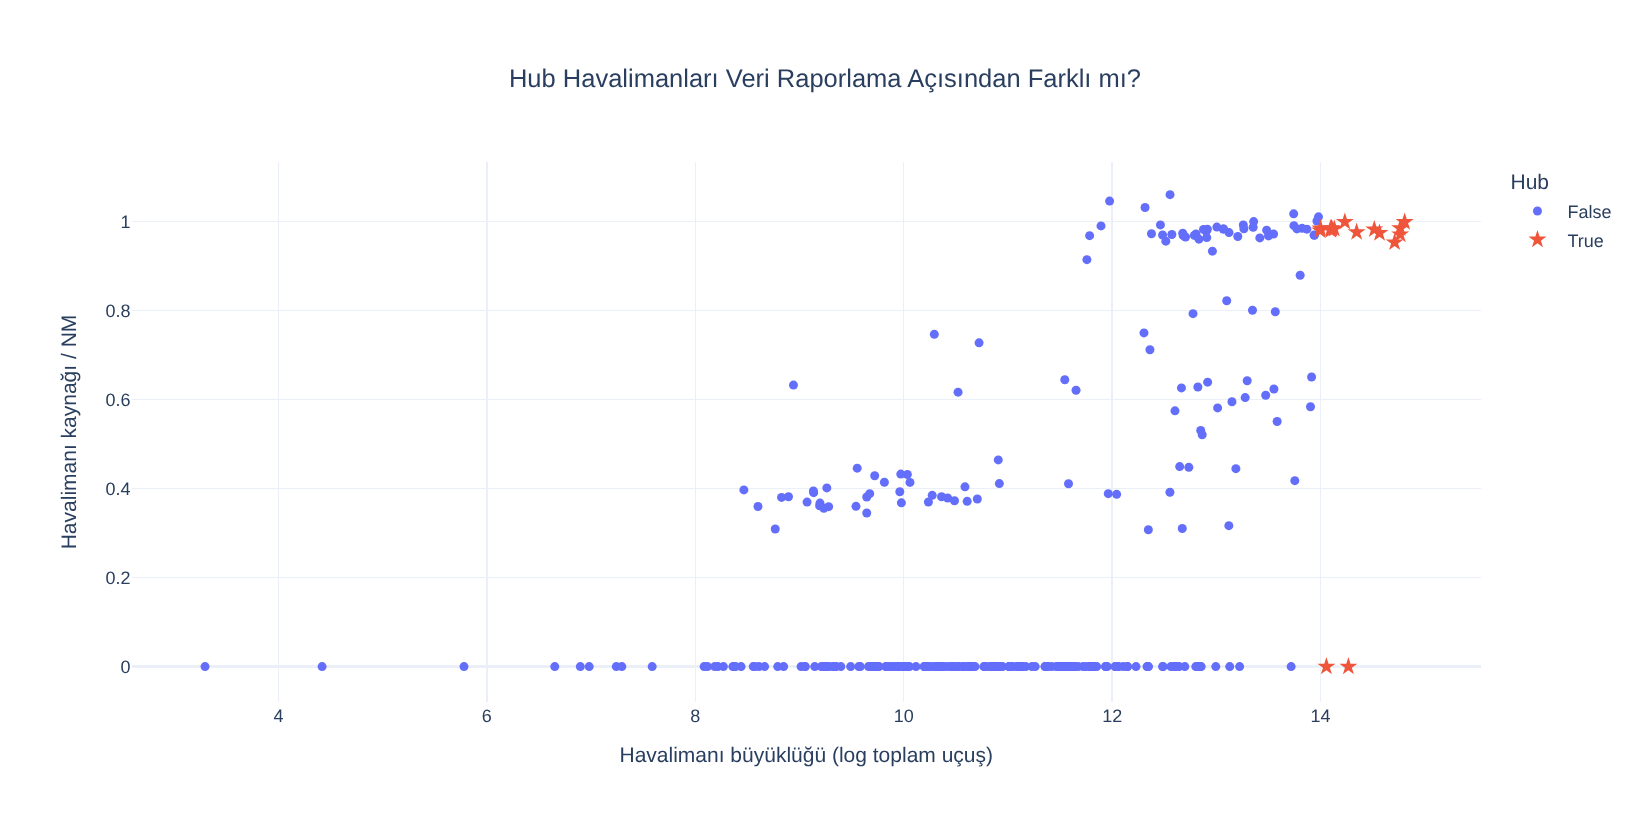

In [6]:
def iqr_flags(s):
    s = s.dropna()
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    lo, hi = q1 - 1.5*iqr, q3 + 1.5*iqr
    return lo, hi

outlier_summary = []
for c in ["FLT_TOT_1","FLT_TOT_IFR_2"]:
    lo, hi = iqr_flags(df[c])
    outlier_summary.append([c, lo, hi, (df[c] > hi).sum(), (df[c] < lo).sum()])
outlier_summary = pd.DataFrame(outlier_summary, columns=["metric","iqr_low","iqr_high","high_outliers","low_outliers"])
display(outlier_summary)


display(df.sort_values("FLT_TOT_1", ascending=False).head(10)[
    ["FLT_DATE","APT_NAME","APT_ICAO","STATE_NAME","FLT_TOT_1","FLT_TOT_IFR_2"]
])


airport_src = (
    df
    .groupby(["APT_ICAO", "APT_NAME"], as_index=False)
    .agg(
        total_flights=("FLT_TOT_1", "sum"),
        total_apt=("FLT_TOT_IFR_2", "sum")
    )
)


airport_src["source_ratio"] = airport_src["total_apt"] / airport_src["total_flights"]
airport_src["log_size"] = np.log1p(airport_src["total_flights"])


viz_catalog_scatter = pd.DataFrame([
    {
        "Grafik": "Hub Havalimanları Veri Raporlama Açısından Farklı mı?",
        "Mark (İşaret)": "Nokta (Circle) + Yıldız (Star)",
        "X Kanalı": "Havalimanı büyüklüğü (log toplam uçuş)",
        "Y Kanalı": "Havalimanı kaynağı / NM oranı",
        "Renk Kanalı": "Hub durumu (True / False)",
        "Şekil Kanalı": "Hub olanlar yıldız, diğerleri daire",
        "Veri Türü (X)": "Ratio (log dönüşümlü nicel)",
        "Veri Türü (Y)": "Ratio (oran)",
        "Analitik Rol": "Measure vs Measure + Segment",
        "Amaç": "Hub havalimanlarının veri raporlama profili diğerlerinden farklı mı görmek",
        "Sorduğu Soru": "En büyük %5’lik (hub) havalimanları iki kaynağın uyumu açısından ayrışıyor mu?"
    }
])

display(viz_catalog_scatter)


threshold = airport_src["total_flights"].quantile(0.95)
airport_src["hub"] = airport_src["total_flights"] >= threshold

fig = px.scatter(
    airport_src,
    x="log_size",
    y="source_ratio",
    color="hub",
    hover_name="APT_NAME",
    title="Hub Havalimanları Veri Raporlama Açısından Farklı mı?",
    labels={"log_size": "Havalimanı büyüklüğü (log toplam uçuş)", "source_ratio": "Havalimanı kaynağı / NM", "hub": "Hub"}
)

fig.update_layout(template="plotly_white", title={"x":0.5})


fig.update_traces(marker=dict(symbol="circle"))


fig.for_each_trace(
    lambda t: t.update(marker=dict(symbol="star", size=9))
    if t.name == "True" else None
)

fig.show()

## Analize Giren Veri Setinin Tanımlanması ve Filtreleme Süreci

Bu çalışmada kullanılan ham veri seti, 2016-2022 dönemine ait aylık havalimanı bazlı uçuş kayıtlarını içermektedir. Ancak zamansal analizler, kaynak karşılaştırmaları ve dağılım incelemeleri yapılabilmesi için verinin belirli asgari kalite koşullarını sağlaması gerekmektedir. Bu nedenle analizden önce veriye bir geçerlilik filtresi uygulanmıştır.

Bu filtreleme ile oluşturulan veri kümesi, çalışmanın geri kalanında kullanılan analiz setini temsil etmektedir.

Bu sonuçlar şu noktaları ortaya koymaktadır:

*   Ham veri setinde 688.099 aylık gözlem ve 332 benzersiz havalimanı bulunmaktadır.
*   Zaman bilgisi (FLT_DATE) ve toplam uçuş bilgisi (FLT_TOT_1) açısından veri büyük ölçüde eksiksizdir.
*   Ancak toplam uçuşu sıfır olan gözlemler analizden çıkarıldığında, yaklaşık **1.021** kayıt filtrelenmiştir.
*   Buna karşın, havalimanı sayısı değişmemiştir. Yani hiçbir havalimanı tamamen veri dışı kalmamış, sadece bazı aylık gözlemler elenmiştir.

Bu durum, veri setinin hem geniş kapsamlı hem de zamansal olarak dengeli olduğunu göstermektedir.

In [7]:
analysis_df = df[
    df["FLT_DATE"].notna() &
    df["FLT_TOT_1"].notna() &
    (df["FLT_TOT_1"] > 0)
].copy()


analysis_df["source_ratio"] = analysis_df["FLT_TOT_IFR_2"] / analysis_df["FLT_TOT_1"]


n_rows_clean = analysis_df.shape[0]
n_airports_clean = analysis_df["APT_ICAO"].nunique()

print("TEMİZLENMİŞ / ANALİZE GİREN VERİ")
print("-" * 45)
print(f"Toplam kayıt (satır) sayısı      : {n_rows_clean}")
print(f"Benzersiz havalimanı sayısı      : {n_airports_clean}")

summary = pd.DataFrame({
    "Aşama": [
        "Ham veri",
        "Geçerli tarih",
        "Geçerli toplam uçuş",
        "Analiz seti"
    ],
    "Kayıt Sayısı": [
        df.shape[0],
        df["FLT_DATE"].notna().sum(),
        df["FLT_TOT_1"].notna().sum(),
        analysis_df.shape[0]
    ],
    "Havalimanı Sayısı": [
        df["APT_ICAO"].nunique(),
        df.loc[df["FLT_DATE"].notna(), "APT_ICAO"].nunique(),
        df.loc[df["FLT_TOT_1"].notna(), "APT_ICAO"].nunique(),
        analysis_df["APT_ICAO"].nunique()
    ]
})

display(summary)

TEMİZLENMİŞ / ANALİZE GİREN VERİ
---------------------------------------------
Toplam kayıt (satır) sayısı      : 687078
Benzersiz havalimanı sayısı      : 332


,Aşama,Kayıt Sayısı,Havalimanı Sayısı
0,Ham veri,688099,332
1,Geçerli tarih,688099,332
2,Geçerli toplam uçuş,688099,332
3,Analiz seti,687078,332


## Dağılım Analizi: *(ECDF ve Logaritmik Histogram ile Aylık Uçuş Yoğunluğu)*

Bu kod bloğunda, Avrupa’daki havalimanlarının aylık toplam uçuş hacimlerinin dağılım yapısını daha derinlemesine incelemek amacıyla iki tamamlayıcı görselleştirme üretilmiştir:
(i) Ampirik kümülatif dağılım fonksiyonu (ECDF) ve
(ii) logaritmik ölçekte histogram ve yoğunluk eğrisi (KDE).

Bu analiz şu temel soruya yanıt aramaktadır:

*Avrupa’daki havalimanlarının aylık uçuş hacimleri dengeli mi dağılmıştır, yoksa trafik az sayıda merkezde mi yoğunlaşmaktadır? italik metin*

### Veri Dönüşümü ve Yöntem

Öncelikle aylık toplam uçuş sayısı (FLT_TOT_1) değişkeni için logaritmik dönüşüm uygulanmıştır.

Bu dönüşümün amacı, özellikle Frankfurt, Paris CDG veya Amsterdam gibi büyük merkez havalimanlarının çok yüksek uçuş değerleri nedeniyle ortaya çıkan sağa çarpık (right-skewed) dağılımı daha dengeli bir ölçeğe taşımaktır. log(1 + x) formu, sıfır değerlerin matematiksel sorun yaratmasını önlerken, aşırı büyük değerlerin görsel analiz üzerindeki baskın etkisini azaltmaktadır.

Ardından iki temel görselleştirme üretilmiştir:

*   ECDF ile kümülatif dağılımın,

*   Logaritmik histogram + KDE ile yoğunluk yapısının

birlikte incelenmesi sağlanmıştır.

### Grafik 1: Toplam Aylık Uçuş Sayısının Kümülatif Dağılımı (ECDF)
X ekseni: Aylık toplam uçuş sayısını (FLT_TOT_1),

Y ekseni: Bu değere kadar olan gözlemlerin toplam içindeki yüzdesini göstermektedir.

Grafik üzerinde ayrıca %80’lik persentil hem yatay hem dikey referans çizgileriyle işaretlenmiştir. Bu eşik, gözlemlerin %80’inin hangi uçuş düzeyinin altında toplandığını görsel olarak ortaya koymaktadır.

Grafik, eğrinin başlangıçta çok hızlı yükselip daha sonra yataylaştığını göstermektedir. Bu durum şu anlama gelir:

Gözlemlerin büyük bir bölümü düşük ve orta düzey uçuş hacmine sahip havalimanlarına aittir.

Buna karşılık, gözlemlerin küçük bir kısmı çok yüksek uçuş değerlerine sahiptir.

ECDF’den okunan yaklaşık eşik, aylık 180-200 uçuş civarındadır. Yani gözlemlerin yaklaşık %80’i bu değerin altında kalmaktadır. Ancak bu, uçuşların %80’inin bu aralıkta gerçekleştiği anlamına gelmez. Tam tersine, uçuşların büyük bir kısmı, geri kalan %20’lik yüksek trafikli dilimde yer alan büyük merkez havalimanları tarafından üretilmektedir.

Bu yapı, Avrupa hava taşımacılığı ağının merkez-çevre (hub-spoke) karakterini açıkça yansıtmaktadır.

### Grafik 2: Logaritmik Ölçekte Toplam Aylık Uçuş Sayısı Dağılımı

İkinci görselleştirmede, logaritmik ölçekte dönüştürülmüş uçuş sayıları için histogram ve KDE (Kernel Density Estimation) eğrisi birlikte çizilmiştir. Histogram gözlemlerin frekansını, KDE ise bu dağılımın pürüzsüz yoğunluk tahminini göstermektedir.

Bu grafik, dağılımın tek tepe noktalı basit bir yapıdan ziyade, çok katmanlı bir yapıya sahip olduğunu ortaya koymaktadır:



*   Düşük log değerlerde küçük ve yerel havalimanları,
*   Orta değerlerde bölgesel merkezler,
*   Yüksek log değerlerde ise büyük uluslararası hub havalimanları ayrı yoğunluk bölgeleri oluşturmaktadır.

Logaritmik dönüşüm sayesinde, ham ölçekte neredeyse görünmez hâle gelen orta ölçekli farklar da belirginleşmiş ve havalimanlarının operasyonel ölçekleri daha net biçimde ayrışmıştır.

### Yorumsal Sonuç
ECDF ve logaritmik histogram birlikte değerlendirildiğinde, Avrupa uçuş trafiğinin dengeli dağılmadığı, aksine az sayıda büyük merkezde yoğunlaştığı açıkça görülmektedir. Bu sonuç, ilerleyen aşamalarda yapılan outlier analizi, hub ve veri raporlama ilişkisi ve mekânsal yoğunluk haritalarının neden anlamlı olduğunu da açıklamaktadır.

Başka bir deyişle, burada gözlenen dağılım çarpıklığı, Avrupa hava taşımacılığı sisteminin yapısal bir özelliği olup, Frankfurt, Paris CDG ve Amsterdam gibi hub havalimanlarının ağın omurgasını oluşturduğunu göstermektedir.

,Grafik,Mark (İşaret),Channel (Görsel Kanal),Veri Türü,Ölçek Türü,Analitik Rol
0,ECDF,Çizgi,x-konumu,Aylık toplam uçuş sayısı,Ratio,Measure
1,ECDF,Çizgi,y-konumu,Kümülatif oran,Ratio,Measure
2,ECDF,Referans çizgisi,x / y konumu,%80 eşik,Ratio,Measure
3,Log Histogram,Eğri (KDE),x–y konumu,Yoğunluk tahmini,Ratio,Measure


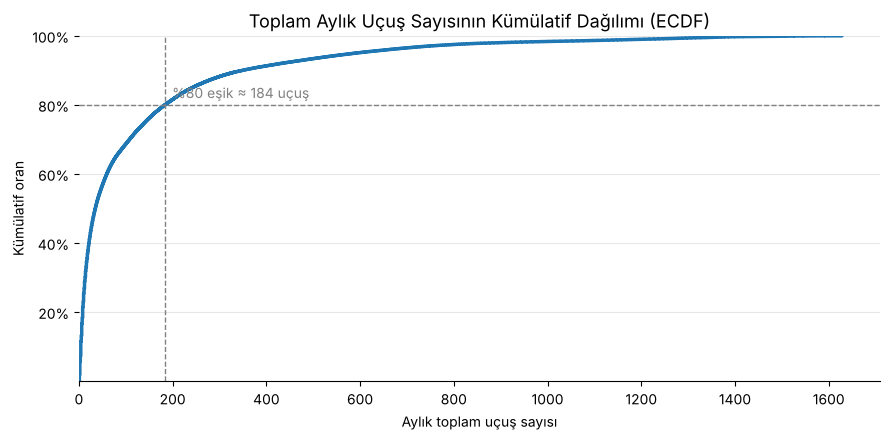

,Bileşen,Mark (İşaret),Channel (Görsel Kanal),Veri Türü,Ölçek Türü,Veri Yapısı,Analitik Rol
0,Histogram,Dikdörtgen (Bar),x-konumu,log(1 + aylık uçuş sayısı),Interval,Nicel,Measure
1,Histogram,Dikdörtgen (Bar),yükseklik,Gözlem yoğunluğu,Ratio,Nicel,Measure
2,KDE,Eğri (Line),x–y konumu,Yoğunluk tahmini,Ratio,Nicel,Measure


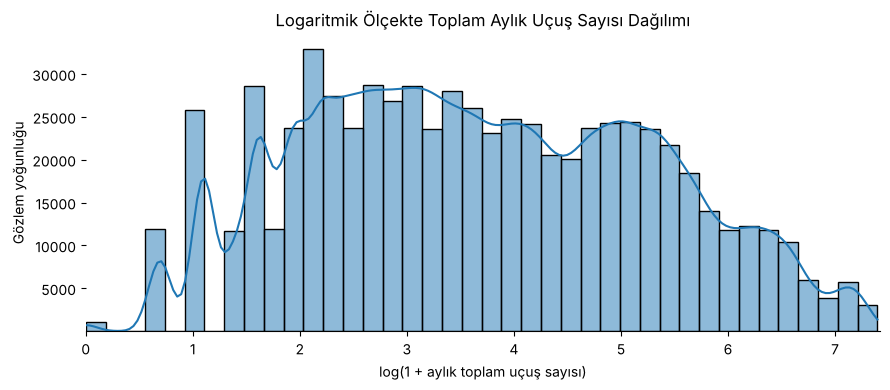

In [8]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FixedLocator, FuncFormatter

viz_catalog = pd.DataFrame({
    "Grafik": [
        "ECDF", "ECDF", "ECDF",
         "Log Histogram"
    ],
    "Mark (İşaret)": [
        "Çizgi", "Çizgi", "Referans çizgisi",
         "Eğri (KDE)"
    ],
    "Channel (Görsel Kanal)": [
        "x-konumu", "y-konumu", "x / y konumu",
         "x–y konumu"
    ],
    "Veri Türü": [
        "Aylık toplam uçuş sayısı",
        "Kümülatif oran",
        "%80 eşik",
        "Yoğunluk tahmini"
    ],
    "Ölçek Türü": [
        "Ratio", "Ratio", "Ratio",
         "Ratio"
    ],
    "Analitik Rol": [
        "Measure", "Measure", "Measure",
         "Measure"
    ]
})


display(viz_catalog)

if "flt_tot_log1p" not in df.columns:
    df["flt_tot_log1p"] = np.log1p(df["FLT_TOT_1"])


x = df["FLT_TOT_1"].dropna().sort_values()
p80 = x.quantile(0.80)

plt.figure(figsize=(9,4.5))
ax = sns.ecdfplot(x, linewidth=2.5, color="#1f77b4")

ax.axhline(0.8, color="gray", linestyle="--", linewidth=1)
ax.axvline(p80, color="gray", linestyle="--", linewidth=1)

ax.text(
    p80 + 15, 0.82,
    f"%80 eşik ≈ {int(p80)} uçuş",
    fontsize=10,
    color="gray",
    ha="left"
)

ax.set_title("Toplam Aylık Uçuş Sayısının Kümülatif Dağılımı (ECDF)", fontsize=13)
ax.set_xlabel("Aylık toplam uçuş sayısı")
ax.set_ylabel("Kümülatif oran")


ax.set_xlim(left=0)

ax.yaxis.set_major_locator(FixedLocator([0.2, 0.4, 0.6, 0.8, 1.0]))
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{int(v*100)}%"))

ax.grid(axis="y", alpha=0.3)
sns.despine(left=True, bottom=False)
plt.tight_layout()
plt.show()


viz_catalog_log = pd.DataFrame({
    "Bileşen": [
        "Histogram", "Histogram", "KDE"
    ],
    "Mark (İşaret)": [
        "Dikdörtgen (Bar)",
        "Dikdörtgen (Bar)",
        "Eğri (Line)"
    ],
    "Channel (Görsel Kanal)": [
        "x-konumu",
        "yükseklik",
        "x–y konumu"
    ],
    "Veri Türü": [
        "log(1 + aylık uçuş sayısı)",
        "Gözlem yoğunluğu",
        "Yoğunluk tahmini"
    ],
    "Ölçek Türü": [
        "Interval",
        "Ratio",
        "Ratio"
    ],
    "Veri Yapısı": [
        "Nicel",
        "Nicel",
        "Nicel"
    ],
    "Analitik Rol": [
        "Measure",
        "Measure",
        "Measure"
    ]
})

display(viz_catalog_log)



plt.figure(figsize=(9,4))
ax = sns.histplot(
    df["flt_tot_log1p"].dropna(),
    bins=40,
    kde=True
)

ax.set_title("Logaritmik Ölçekte Toplam Aylık Uçuş Sayısı Dağılımı")
ax.set_xlabel("log(1 + aylık toplam uçuş sayısı)")
ax.set_ylabel("Gözlem yoğunluğu")

ax.set_xlim(left=0)
ax.set_xlim(right=7.42)

ax.xaxis.set_major_locator(FixedLocator([0, 1, 2, 3, 4, 5, 6, 7]))
ax.yaxis.set_major_locator(FixedLocator([5000, 10000, 15000, 20000, 25000, 30000]))
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{int(v)}"))

sns.despine(left=True, bottom=False)
plt.tight_layout()
plt.show()

# Uçuş Trafiğinin Havalimanları Arasında Yoğunlaşmasının İncelenmesi

Bu aşamada, toplam uçuş trafiğinin havalimanları arasında nasıl paylaşıldığını incelemek amacıyla kümülatif pay analizi gerçekleştirilmiştir. Analizin temel amacı, Avrupa’daki toplam uçuş trafiğinin ne kadarının az sayıda büyük havalimanı tarafından üretildiğini nicel olarak ortaya koymaktır.

Öncelikle, veri seti havalimanı bazında gruplanmış; her bir havalimanı için tüm dönemleri kapsayan toplam uçuş sayısı (FLT_TOT_1) hesaplanmıştır. Bu toplamlar, en yüksekten en düşüğe doğru sıralanarak, trafik hacmi açısından öne çıkan havalimanlarının belirlenmesi sağlanmıştır.

Ardından, her bir havalimanının ürettiği uçuş sayısının, tüm havalimanlarının toplam uçuş sayısına oranı kümülatif olarak hesaplanmıştır. Bu oran, kümülatif pay (cumulative share) olarak adlandırılmış ve her bir havalimanının sistem içindeki birikimli katkısını göstermektedir.

## Sonuçların Yorumlanması

Toplam havalimanı sayısı ≈ 332
80% uçuşu üretenler ≈ 83
Yani:
%25’lik bir azınlık, %80’lik trafiği taşıyor.

Toplam uçuşların %80’inin yalnızca 83 havalimanında yoğunlaşması, Avrupa hava ulaşım ağının güçlü bir merkez-çevre (hub-spoke) yapıya sahip olduğunu nicel olarak doğrulamaktadır.

In [9]:
airport_tot = (df.groupby(["APT_ICAO","APT_NAME"], as_index=False)["FLT_TOT_1"]
                 .sum()
                 .sort_values("FLT_TOT_1", ascending=False))
airport_tot["cum_share"] = airport_tot["FLT_TOT_1"].cumsum() / airport_tot["FLT_TOT_1"].sum()

display(airport_tot.head(15))


k = (airport_tot["cum_share"] <= 0.80).sum()
print("Toplam uçuşun %80'ini üreten havalimanı sayısı:", k)


,APT_ICAO,APT_NAME,FLT_TOT_1,cum_share
43,EHAM,Amsterdam - Schiphol,2694025,0.030946
238,LFPG,Paris-Charles-de-Gaulle,2581673,0.060601
8,EDDF,Frankfurt,2581524,0.090254
36,EGLL,London - Heathrow,2446474,0.118356
170,LEMD,Madrid - Barajas,2117063,0.142675
13,EDDM,Munich,2013524,0.165804
156,LEBL,Barcelona,1699766,0.185328
321,LTBA,Istanbul Atatürk,1570488,0.203368
283,LIRF,Rome - Fiumicino,1518100,0.220806
318,LSZH,Zürich,1372321,0.236570


Toplam uçuşun %80'ini üreten havalimanı sayısı: 83


## Zaman Boyutu Analizi *(Aylık Uçuş Trendleri ve Mevsimsellik)*

Bu aşamada amaç, Avrupa havalimanları ağındaki toplam uçuş trafiğinin zaman içindeki davranışını incelemek, uzun dönemli eğilimleri ve mevsimsel dalgalanmaları ortaya koymaktır. Bunun için iki tamamlayıcı zaman-temelli görselleştirme üretilmiştir:

*   Aylık toplam uçuş zaman serisi (line chart)
*   Yıl × Ay mevsimsellik matrisi (heatmap)

Bu iki grafik birlikte, sistemin hem zaman boyunca nasıl evrildiğini hem de yıl içindeki ritmini göstermektedir.

1. Aylık Toplam Uçuş Zaman Serisi

Öncelikle tüm havalimanları için aylık toplam uçuş sayıları hesaplanmıştır. Bunun için uçuş tarihleri (FLT_DATE) aylık başlangıçlara (MS) göre gruplanmış ve her ay için toplam uçuş hacmi elde edilmiştir.

Bu değerler bir çizgi grafiği ile zamana karşı çizilmiştir.

Grafiğin gösterdiği yapı

Grafik Avrupa hava trafiğinin üç temel davranışını açık biçimde ortaya koymaktadır:

(i) Uzun dönem trend

2016’dan 2019 sonuna kadar uçuş sayıları düzenli ve istikrarlı biçimde artmaktadır. Bu, Avrupa hava ulaşım sisteminin pandemi öncesi dönemde büyüyen ve genişleyen bir ağ yapısına sahip olduğunu göstermektedir.

(ii) Mevsimsel dalgalanma

Her yıl aynı örüntü tekrar etmektedir:

*   İlkbaharda artış
*   Yaz aylarında zirve
*   Sonbaharda düşüş
*   Kış aylarında minimum

Bu, turizm, tatil dönemleri ve hava koşullarıyla uyumlu güçlü bir mevsimsellik sinyali olduğunu gösterir.

(iii) Yapısal kırılma (2020)

2020 yılının ilk aylarından itibaren ani ve dramatik bir çöküş görülmektedir. Bu düşüş, COVID-19 pandemisinin Avrupa hava trafiği üzerindeki sistemik etkisini doğrudan yansıtmaktadır. Uçuş hacmi birkaç ay içinde normal seviyesinin çok küçük bir bölümüne gerilemiştir.

Sonraki yıllarda kademeli bir toparlanma görülse de, sistemin eski denge seviyesine dönüşü zamana yayılmıştır. Bu, havacılık ağının şoklara karşı hassas ve yavaş toparlanan bir yapıda olduğunu göstermektedir.

2. Mevsimsellik Matrisi (Yıl × Ay Isı Haritası)

Zaman serisinin genel trendini tamamlayıcı olarak, uçuş trafiğinin yıl içindeki dağılımını daha net görmek için bir mevsimsellik matrisi oluşturulmuştur.

Bu grafikte:

X ekseni: Ay

Y ekseni: Yıl

Renk: O ayın toplam uçuş hacmi

olacak şekilde bir yoğunluk haritası çizilmiştir.

Grafiğin analitik anlamı

Bu ısı haritası, üç önemli yapıyı aynı anda göstermektedir:

(i) Yıllar arası farklar

2016–2019 döneminde yaz aylarının giderek daha parlak hale gelmesi, sistemin her yıl daha yüksek zirveler ürettiğini göstermektedir. Bu, büyüyen bir ağın görsel imzasıdır.

2020 satırında ise tüm ayların koyu renge dönmesi, pandemi etkisinin tüm yıl boyunca sistemik olduğunu ortaya koymaktadır.

(ii) Mevsimsel ritim

Her yıl aynı desen tekrar eder:

Mayıs–Eylül yüksek yoğunluk

Ocak–Şubat ve Kasım–Aralık düşük yoğunluk

Bu, havacılık sisteminin doğasında var olan güçlü bir mevsimsel osilasyon olduğunu doğrular.

(iii) Sistem belleği

Pandemi sonrası yıllarda renklerin yavaş yavaş açılması, sistemin eski kapasitesine doğru geri dönmeye çalıştığını gösterir. Bu, havacılık ağının bir tür toparlanma dinamiğine sahip olduğunu ve ani şoklardan sonra dengeye doğru evrildiğini ortaya koyar.

,month_start,total_flights
0,2016-01-01 00:00:00+00:00,1042854
1,2016-02-01 00:00:00+00:00,1045392
2,2016-03-01 00:00:00+00:00,1167319
3,2016-04-01 00:00:00+00:00,1240486
4,2016-05-01 00:00:00+00:00,1368312


,Grafik,Mark,X Kanalı,Y Kanalı,Renk Kanalı,Veri Türü (X),Veri Türü (Y),Nitelik,Rol,Amaç,Tasarım Kararı
0,Aylık Uçuş Zaman Serisi,Line (Çizgi),"Zaman (Yıl = ana tick, Ay = minor tick)",Toplam uçuş sayısı,Yok,Interval (zaman),Ratio (sayım),Nicel (Quantitative),Measure (ölçüm),Uzun dönem trendi ve yıl içi mevsimsel dalgalanmaları aynı anda göstermek,"Yıllar ana referans olarak, aylar ise zamanın akışını hissettiren mikro işaretler (minor ticks)"


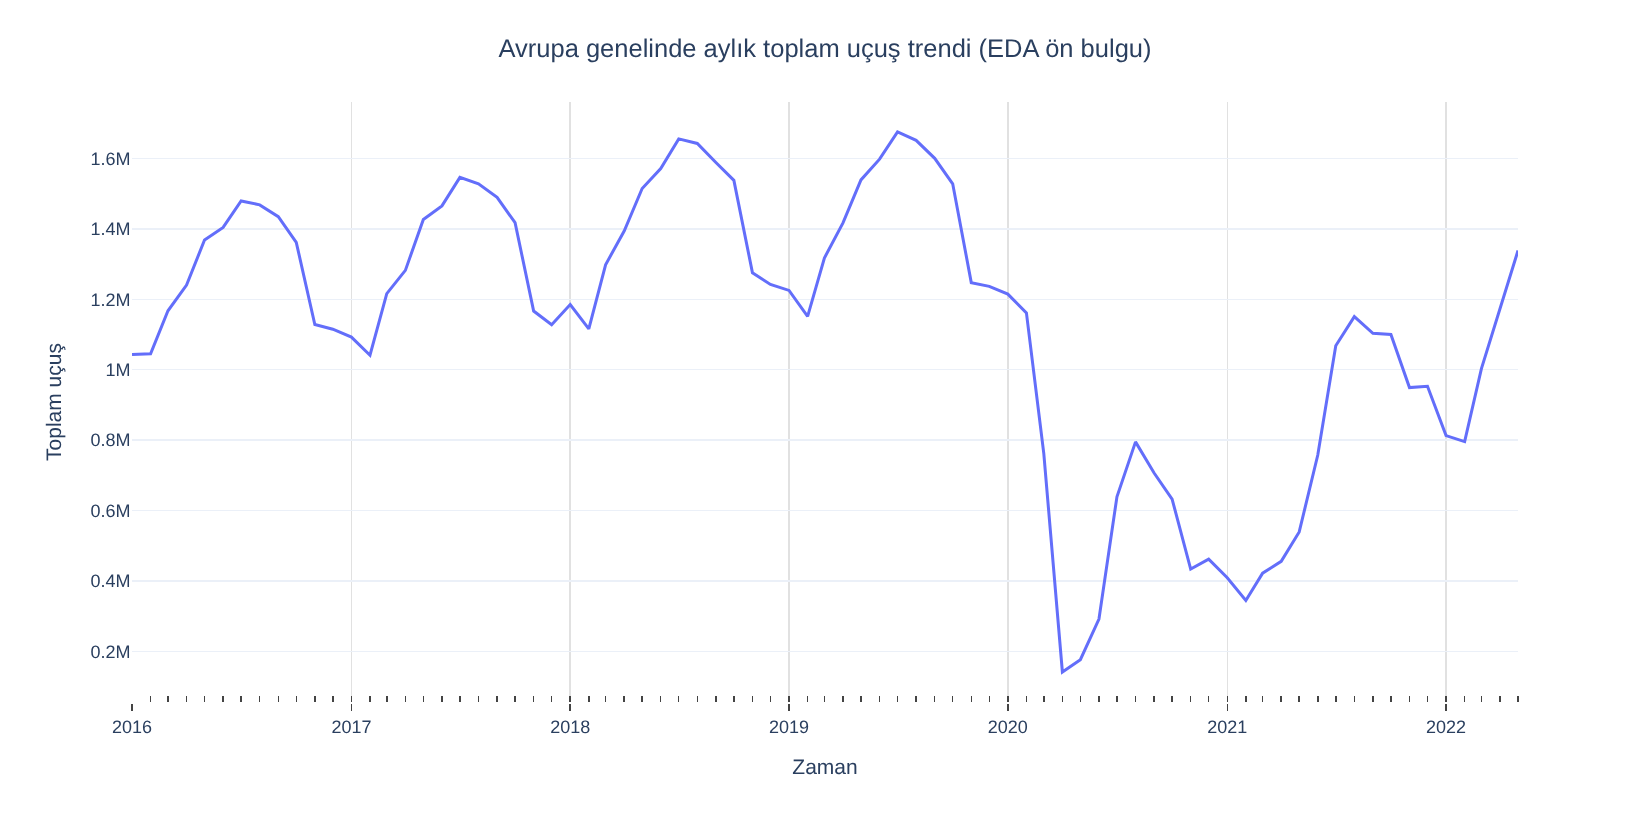

,Grafik,Mark,X Kanalı,Y Kanalı,Renk Kanalı,Veri Türü (X),Veri Türü (Y),Veri Türü (Renk),Nitelik,Rol,Amaç
0,Mevsimsellik Matrisi,Rect (Dikdörtgen),Ay,Yıl,Toplam uçuş sayısı,Kategorik,Interval (zaman),Ratio (sayım),Nicel (Quantitative),Measure (ölçüm),Mevsimsel örüntülerin yıllar bazında karşılaştırılması


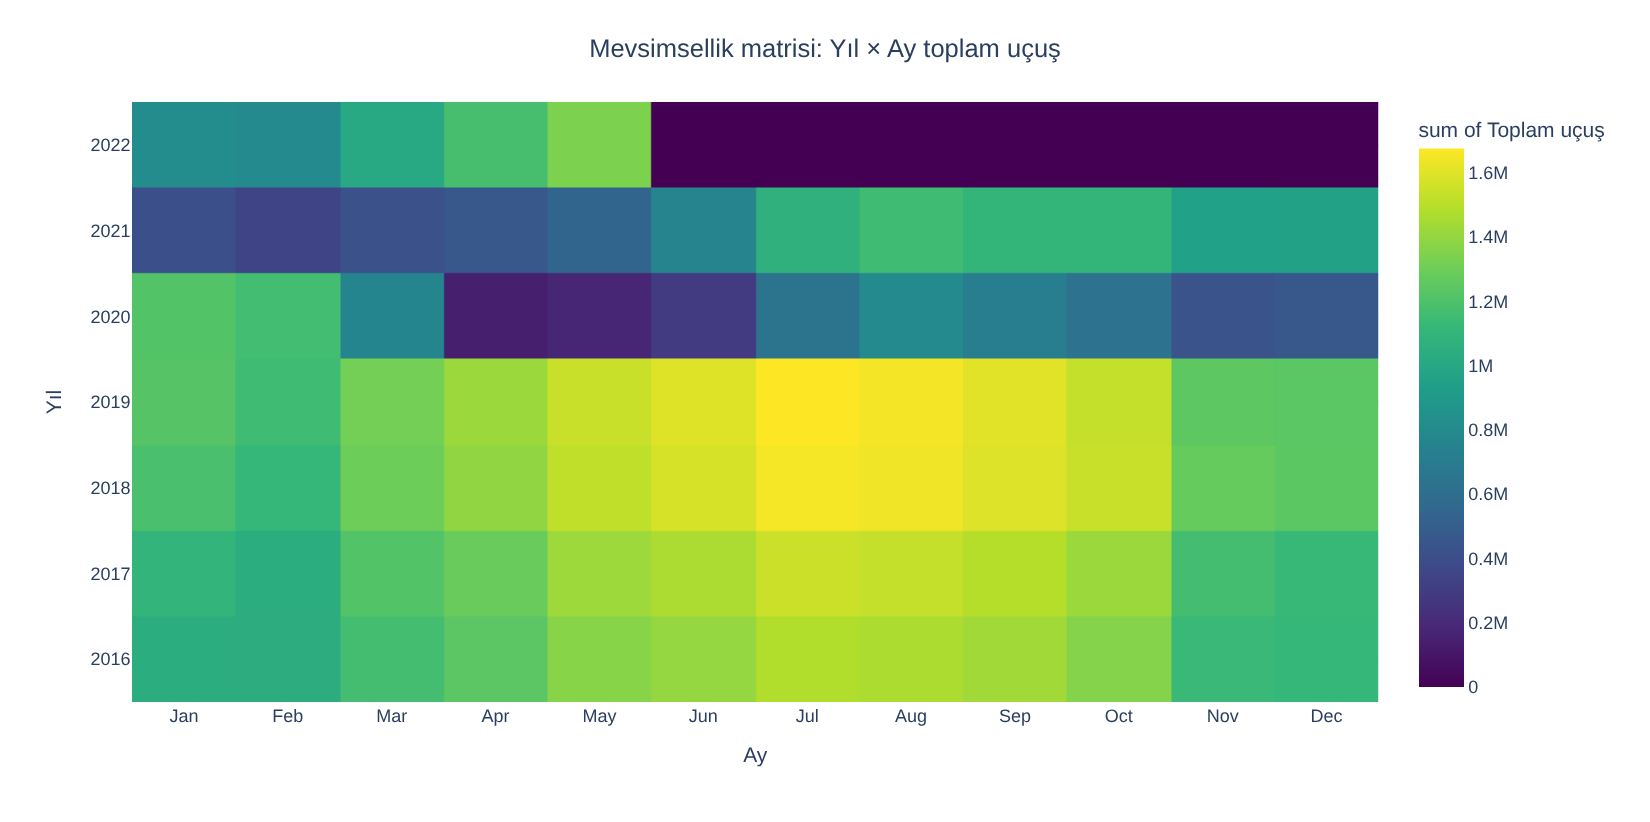

In [10]:
import pandas as pd
import plotly.express as px



df["FLT_DATE"] = pd.to_datetime(df["FLT_DATE"], errors="coerce")

tmp = df.dropna(subset=["FLT_DATE"]).copy()

monthly = (
    tmp.set_index("FLT_DATE")["FLT_TOT_1"]
       .resample("MS")
       .sum()
       .reset_index()
       .rename(columns={
           "FLT_DATE": "month_start",
           "FLT_TOT_1": "total_flights"
       })
)

display(monthly.head())

catalog_ts = pd.DataFrame([{
    "Grafik": "Aylık Uçuş Zaman Serisi",
    "Mark": "Line (Çizgi)",
    "X Kanalı": "Zaman (Yıl = ana tick, Ay = minor tick)",
    "Y Kanalı": "Toplam uçuş sayısı",
    "Renk Kanalı": "Yok",
    "Veri Türü (X)": "Interval (zaman)",
    "Veri Türü (Y)": "Ratio (sayım)",
    "Nitelik": "Nicel (Quantitative)",
    "Rol": "Measure (ölçüm)",
    "Amaç": "Uzun dönem trendi ve yıl içi mevsimsel dalgalanmaları aynı anda göstermek",
    "Tasarım Kararı": "Yıllar ana referans olarak, aylar ise zamanın akışını  hissettiren mikro işaretler (minor ticks)"
}])

display(catalog_ts)

monthly["month_label"] = monthly["month_start"].dt.strftime("%Y-%m")

fig_ts = px.line(
    monthly,
    x="month_start",
    y="total_flights",
    hover_data={"month_label": True},
    labels={
        "month_start": "Zaman",
        "total_flights": "Toplam uçuş",
        "month_label": "Ay"
    }
)


airport_src = (
    df
    .groupby(["APT_ICAO", "APT_NAME"], as_index=False)
    .agg(
        total_flights=("FLT_TOT_1", "sum"),
        total_apt=("FLT_TOT_IFR_2", "sum")
    )
)

fig_ts.update_layout(
    title={
        "text": "Avrupa genelinde aylık toplam uçuş trendi (EDA ön bulgu)",
        "x": 0.5
    },
    template="plotly_white"
)

fig_ts.update_traces(
    hovertemplate=
        "Ay: %{customdata[0]}<br>" +
        "Toplam uçuş: %{y:,.0f}<extra></extra>"
)

fig_ts.update_xaxes(
    dtick="M12",
    tickformat="%Y",
    ticks="outside",
    showgrid=True,
    gridcolor="rgba(180,180,180,0.4)",

    minor=dict(
        dtick="M1",
        ticks="inside",
        showgrid=False,
        ticklen=4
    )
)

fig_ts.update_yaxes(
    title="Toplam uçuş"
)

fig_ts.show()


catalog_heat = pd.DataFrame([
    {
        "Grafik": "Mevsimsellik Matrisi",
        "Mark": "Rect (Dikdörtgen)",
        "X Kanalı": "Ay",
        "Y Kanalı": "Yıl",
        "Renk Kanalı": "Toplam uçuş sayısı",
        "Veri Türü (X)": "Kategorik",
        "Veri Türü (Y)": "Interval (zaman)",
        "Veri Türü (Renk)": "Ratio (sayım)",
        "Nitelik": "Nicel (Quantitative)",
        "Rol": "Measure (ölçüm)",
        "Amaç": "Mevsimsel örüntülerin yıllar bazında karşılaştırılması"
    }
])

display(catalog_heat)



# Son gerçek ayı bul (örnek: 2022-05)
last_date = tmp["FLT_DATE"].max()

heat = (
    tmp[tmp["FLT_DATE"] <= last_date]
    .assign(
        year=tmp["FLT_DATE"].dt.year,
        month=tmp["FLT_DATE"].dt.month
    )
    .groupby(["year", "month"], as_index=False)["FLT_TOT_1"]
    .sum()
)


heat = heat[heat["year"] <= last_date.year]
years = sorted(heat["year"].unique())



heat["month_name"] = pd.to_datetime(
    heat["month"], format="%m"
).dt.strftime("%b")

# Her yılın ayrı bir satırda görünmesi için yıl kategorik (metin) olarak kullanılır
heat["year"] = heat["year"].astype(str)
years = [str(y) for y in years]
month_order = pd.to_datetime(list(range(1, 13)), format="%m").strftime("%b").tolist()

fig_heat = px.density_heatmap(
    heat,
    x="month_name",
    y="year",
    z="FLT_TOT_1",
    histfunc="sum",
    labels={
        "month_name": "Ay",
        "year": "Yıl",
        "FLT_TOT_1": "Toplam uçuş"
    },
    color_continuous_scale="Viridis"
)

fig_heat.update_yaxes(
    categoryorder="array",
    categoryarray=years
)
fig_heat.update_xaxes(categoryorder="array", categoryarray=month_order)



fig_heat.update_layout(
    title={
        "text": "Mevsimsellik matrisi: Yıl × Ay toplam uçuş",
        "x": 0.5,
        "xanchor": "center"
    },
    template="plotly_white"
)

fig_heat.show()


## Soru 1 - *“Zaman içinde uçuş hacmi nasıl değişiyor?”*

Bu sorunun amacı, Avrupa’daki hava trafiğinin yalnızca rastgele dalgalanan bir zaman serisi mi yoksa düzenli, öngörülebilir ve yapısal bir zamansal düzen mi sergilediğini ortaya koymaktır.

Bu temel soru üç alt boyuta ayrılmıştır:

1. Aylık uçuş hacimleri mevsimsel bir döngü gösteriyor mu?
2. Yıllar boyunca uçuş hacmi büyüyor mu, durağan mı, yoksa düşüyor mu?
3. Olağan akıştan sapmalar belirli dönemlerde mi yoğunlaşıyor?

Bu sorunun sorulmasının nedeni şudur:
Hava taşımacılığı talebi doğası gereği yaz-kış döngülerine, turizm sezonlarına ve kriz veya toparlanma dönemlerine son derece duyarlıdır. Bu nedenle zamansal yapı doğru anlaşılmadan, ağın kırılganlığı veya hub etkisi gibi daha ileri analizlerin sağlıklı yapılması mümkün değildir.

Zaman serisi iki temel araçla analiz edilmiştir:

*   Zaman serisi ayrıştırması (Observed - Trend - Seasonal - Residual)
*   Artık (residual) bileşen üzerinde olağan dışı dönemlerin incelenmesi

Kullandığımız Görseller

Bu sorulara yanıt aramak için iki ana görselleştirme kullanılmıştır:

### Zaman Serisi Ayrıştırma Grafiği

Bu grafik, aylık toplam uçuş sayısını dört bileşene ayırır:

Gözlenen (Observed): Gerçek uçuş sayıları

Trend: Uzun dönemli büyüme veya daralma eğilimi

Mevsimsellik: Yıl içinde tekrar eden düzenli dalgalanmalar

Artık (Residual): Beklenen yapının dışında kalan olağan dışı sapmalar

Bu ayrıştırma, uçuş trafiğinin hangi kısmının doğal mevsimsellikten, hangi kısmının yapısal trendden ve hangi kısmının şoklardan kaynaklandığını ayırt etmemizi sağlar.

### Artık Bileşen Üzerinde Olağan Dışı Dönemler

Trend ve mevsimsellik çıkarıldıktan sonra kalan artık bileşen, sistemin “normal” davranıştan ne kadar saptığını gösterir. Bu seri üzerinde z-skor yaklaşımıyla, olağan dışı yüksek veya düşük dönemler işaretlenmiştir.

Bu sayede pandemi, ani talep çöküşleri, beklenmeyen toparlanmalar gibi sistemik şokların zamansal olarak ne zaman yoğunlaştığı nesnel olarak belirlenmiştir.

### Bu Aşamada Ulaşılan Cevaplar

Bu analizlerin sonucunda sorulan sorulara net yanıtlar elde edilmiştir:
1. Aylık uçuş hacimleri mevsimsel bir döngü gösteriyor mu?

Mevsimsellik bileşeni, her yıl yaz aylarında uçuşların arttığını, kış aylarında ise düştüğünü açık biçimde göstermektedir. Bu, Avrupa havacılık sisteminin güçlü bir yaz-kış döngüsüne sahip olduğunu doğrular.

2. Yıllar boyunca uçuş hacmi büyüyor mu, durağan mı, yoksa düşüyor mu?

Trend bileşeni, 2016-2019 arasında sürekli büyüyen bir sistem, 2020’de sert bir kırılma ve 2021 sonrası kademeli bir toparlanma olduğunu ortaya koymaktadır.

3. Olağan akıştan sapmalar belirli dönemlerde mi yoğunlaşıyor?

Artık bileşeni, özellikle 2020 yılı boyunca olağan dışı büyüklükte sapmalar olduğunu göstermektedir. Bu, COVID-19’un hava trafiği üzerinde yarattığı yapısal şoku açık biçimde yansıtmaktadır.

,Özellik,Açıklama
0,Grafik Türü,Zaman serisi ayrıştırma grafiği (çoklu çizgi)
1,Mark (İşaret),Çizgi + işaretleyici (line + marker)
2,X Kanalı,"Zaman (yıl = ana tick, ay = minor tick)"
3,Y Kanalı,Toplam uçuş sayısı / bileşen değeri
4,Ayrım Kanalı,"Bileşen türü (Gözlenen, Trend, Mevsimsellik, Artık)"
5,Zamansal Değişken,month_start
6,Ölçek Türü (X),Interval (zamansal)
7,Ölçek Türü (Y),Ratio (sayım)
8,Veri Türü,Nicel (quantitative)
9,Rol,Measure (ölçüm)


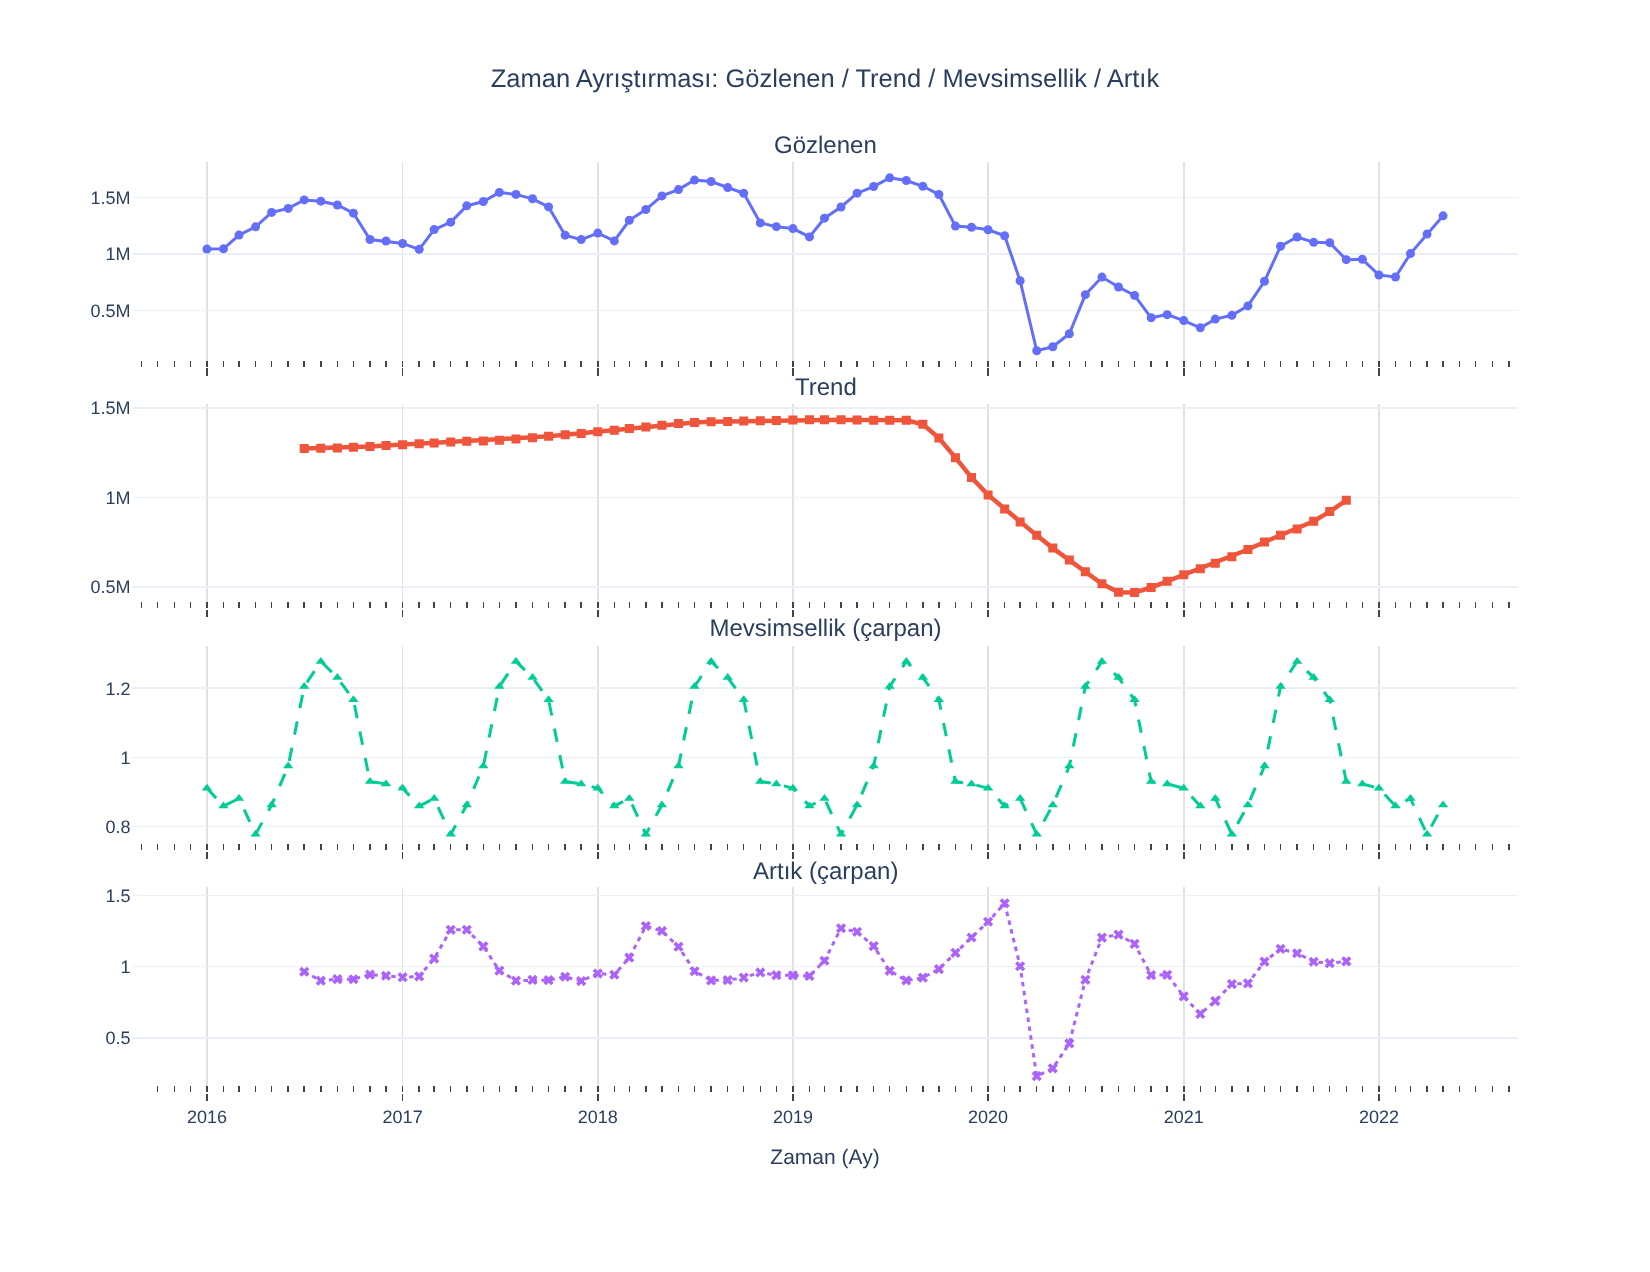

In [11]:
import pandas as pd
from statsmodels.tsa.seasonal import seasonal_decompose
import plotly.graph_objects as go
from plotly.subplots import make_subplots


viz_catalog = pd.DataFrame({
    "Özellik": [
        "Grafik Türü",
        "Mark (İşaret)",
        "X Kanalı",
        "Y Kanalı",
        "Ayrım Kanalı",
        "Zamansal Değişken",
        "Ölçek Türü (X)",
        "Ölçek Türü (Y)",
        "Veri Türü",
        "Rol",
        "Ayırt Edicilik",
        "Amaç",
        "Tasarım Kararı",
        "Etkileşim"
    ],
    "Açıklama": [
        "Zaman serisi ayrıştırma grafiği (çoklu çizgi)",
        "Çizgi + işaretleyici (line + marker)",
        "Zaman (yıl = ana tick, ay = minor tick)",
        "Toplam uçuş sayısı / bileşen değeri",
        "Bileşen türü (Gözlenen, Trend, Mevsimsellik, Artık)",
        "month_start",
        "Interval (zamansal)",
        "Ratio (sayım)",
        "Nicel (quantitative)",
        "Measure (ölçüm)",
        "Çizgi tipi ve işaretleyici sembolleri ile (renkten bağımsız)",
        "Trend, mevsimsellik ve olağan dışı sapmaları birlikte incelemek",
        "Yıllar makro zaman referansı, aylar ise ritmi ve döngüyü gösteren mikro işaretler olarak kodlandı",
        "Hover ile değer okuma"
    ]
})

display(viz_catalog)


ts = monthly.set_index("month_start")["total_flights"].asfreq("MS")
decomp = seasonal_decompose(ts, model="multiplicative", period=12)


hover_month = ts.index.to_series().dt.strftime("%Y-%m")

fig = make_subplots(
    rows=4, cols=1, shared_xaxes=True, vertical_spacing=0.04,
    subplot_titles=("Gözlenen", "Trend", "Mevsimsellik (çarpan)", "Artık (çarpan)")
)


fig.add_trace(
    go.Scatter(
        x=ts.index,
        y=ts.values,
        name="Gözlenen",
        mode="lines+markers",
        line=dict(width=2),
        marker=dict(symbol="circle", size=6),
        customdata=hover_month,
        hovertemplate=
            "Ay: %{customdata}<br>" +
            "Gözlenen: %{y:,.0f}<extra></extra>"
    )
, row=1, col=1)



fig.add_trace(
    go.Scatter(
        x=ts.index,
        y=decomp.trend,
        name="Trend",
        mode="lines+markers",
        line=dict(width=3),
        marker=dict(symbol="square", size=6),
        customdata=hover_month,
        hovertemplate=
            "Ay: %{customdata}<br>" +
            "Trend: %{y:,.0f}<extra></extra>"
    )
, row=2, col=1)



fig.add_trace(
    go.Scatter(
        x=ts.index,
        y=decomp.seasonal,
        name="Mevsimsellik",
        mode="lines+markers",
        line=dict(width=2, dash="dash"),
        marker=dict(symbol="triangle-up", size=6),
        customdata=hover_month,
        hovertemplate=
            "Ay: %{customdata}<br>" +
            "Mevsimsellik: %{y:.3f}<extra></extra>"
    )
, row=3, col=1)


fig.add_trace(
    go.Scatter(
        x=ts.index,
        y=decomp.resid,
        name="Artık",
        mode="lines+markers",
        line=dict(width=2, dash="dot"),
        marker=dict(symbol="x", size=6),
        customdata=hover_month,
        hovertemplate=
            "Ay: %{customdata}<br>" +
            "Artık: %{y:.3f}<extra></extra>"
    )
, row=4, col=1)


fig.update_layout(
    title={
        "text": "Zaman Ayrıştırması: Gözlenen / Trend / Mevsimsellik / Artık",
        "x": 0.5,
        "xanchor": "center"
    },
    template="plotly_white",
    height=800,
    showlegend=False
)

fig.update_xaxes(title_text="Zaman (Ay)", row=4, col=1)
fig.update_xaxes(
    dtick="M12",
    tickformat="%Y",
    ticks="outside",
    showgrid=True,
    gridcolor="rgba(180,180,180,0.4)",

    minor=dict(
        dtick="M1",
        ticks="inside",
        showgrid=False,
        ticklen=4
    )
)


fig.show()


## Soru 1 - *“Zaman içinde uçuş hacmi nasıl değişiyor?”*
### Alt Soru 3 -*“Olağan akıştan sapmalar hangi dönemlerde yoğunlaşıyor?”*

Önceki adımlarda aylık uçuş zaman serisini trend ve mevsimsellik bileşenlerine ayırarak sistemin “beklenen” zamansal davranışını tanımlamıştık. Bu aşamada artık farklı bir soruya odaklanıyoruz:

Trend ve mevsimsellik çıkarıldıktan sonra geriye kalan dalgalanmalar sıradan mı, yoksa bazı dönemler istatistiksel olarak olağan dışı mı?

Bu soruya yanıt verebilmek için zaman serisi ayrıştırmasından elde edilen artık (residual) bileşen kullanılmıştır.

Artık bileşen şu anlama gelir:

“Bu ay gerçekleşen uçuş sayısı, o ay için trend ve mevsimsellik tarafından beklenen değerden ne kadar saptı?”

Ancak bu farkları mutlak değerleriyle karşılaştırmak yanıltıcı olabilir. Bu nedenle artık bileşen z-skor ile standartlaştırılmıştır:

Bu dönüşüm sayesinde:

*   𝑧 ≈ 0 → normal davranış
*   ∣ 𝑧 ∣ büyük → olağan dışı sapma

Bu çalışmada |z| ≥ 3 eşiği kullanılarak istatistiksel olarak anlamlı anomaliler belirlenmiştir.

### Grafikten Okunan Sonuç

Grafik çok net bir yapı ortaya koymaktadır:

2016-2019 döneminde residual z-skorları çoğunlukla -1 ile +1 aralığında kalmaktadır.
Bu, sistemin:

*   trendine
*   mevsimselliğine

uygun biçimde çalıştığını göstermektedir.

2020 baharında ise artık bileşeni ani ve çok güçlü bir şekilde -3 eşiğinin altına düşmektedir. Özellikle 2020-Nisan ve 2020-Mayıs ayları, tüm zaman serisi boyunca görülen en büyük negatif sapmalar olarak işaretlenmiştir.

Bu şu anlama gelir:

Bu aylarda uçuş hacmi, o ay için beklenen normal değerin istatistiksel olarak olağan dışı derecede altına düşmüştür.

Bu bulgu, COVID-19 pandemisi sırasında Avrupa hava trafiğinin neredeyse durma noktasına geldiği dönemi doğrudan ve nicel olarak yansıtmaktadır.

### Soru 1 İçin Nihai Zamansal Sonuç

Soru 1’in üç alt bileşeni birlikte okunduğunda şu tablo ortaya çıkmaktadır:
*   Avrupa hava trafiği güçlü bir mevsimsel ritme sahiptir.
*   2016-2019 arasında sistem istikrarlı bir büyüme trendi göstermektedir.
*   2020’de bu yapı dışsal bir şokla bozulmuş ve bu bozulma residual z-skor ile nesnel biçimde tespit edilmiştir.

Yani zamansal analiz bize şunu söylemektedir:

Hava ulaşım ağı normal koşullarda düzenli ve öngörülebilir bir sistemdir. Ancak büyük krizler ortaya çıktığında bu düzen, ağın tüm düğümlerini etkileyen sistemik kırılmalar üretir.

,Özellik,Açıklama
0,Grafik Türü,Zaman serisi (artık bileşen z-skoru)
1,Mark (İşaret),Çizgi + nokta (anomali işaretleri)
2,X Kanalı,"Zaman (yıl = ana tick, ay = minor tick)"
3,Y Kanalı,Residual z-score
4,Renk Kanalı,Normal / anomali aylar
5,Zamansal Değişken,month_start
6,Ölçek Türü (X),Interval (zaman)
7,Ölçek Türü (Y),Interval (standartlaştırılmış)
8,Veri Türü,Nicel (Quantitative)
9,Rol,Measure (ölçüm)


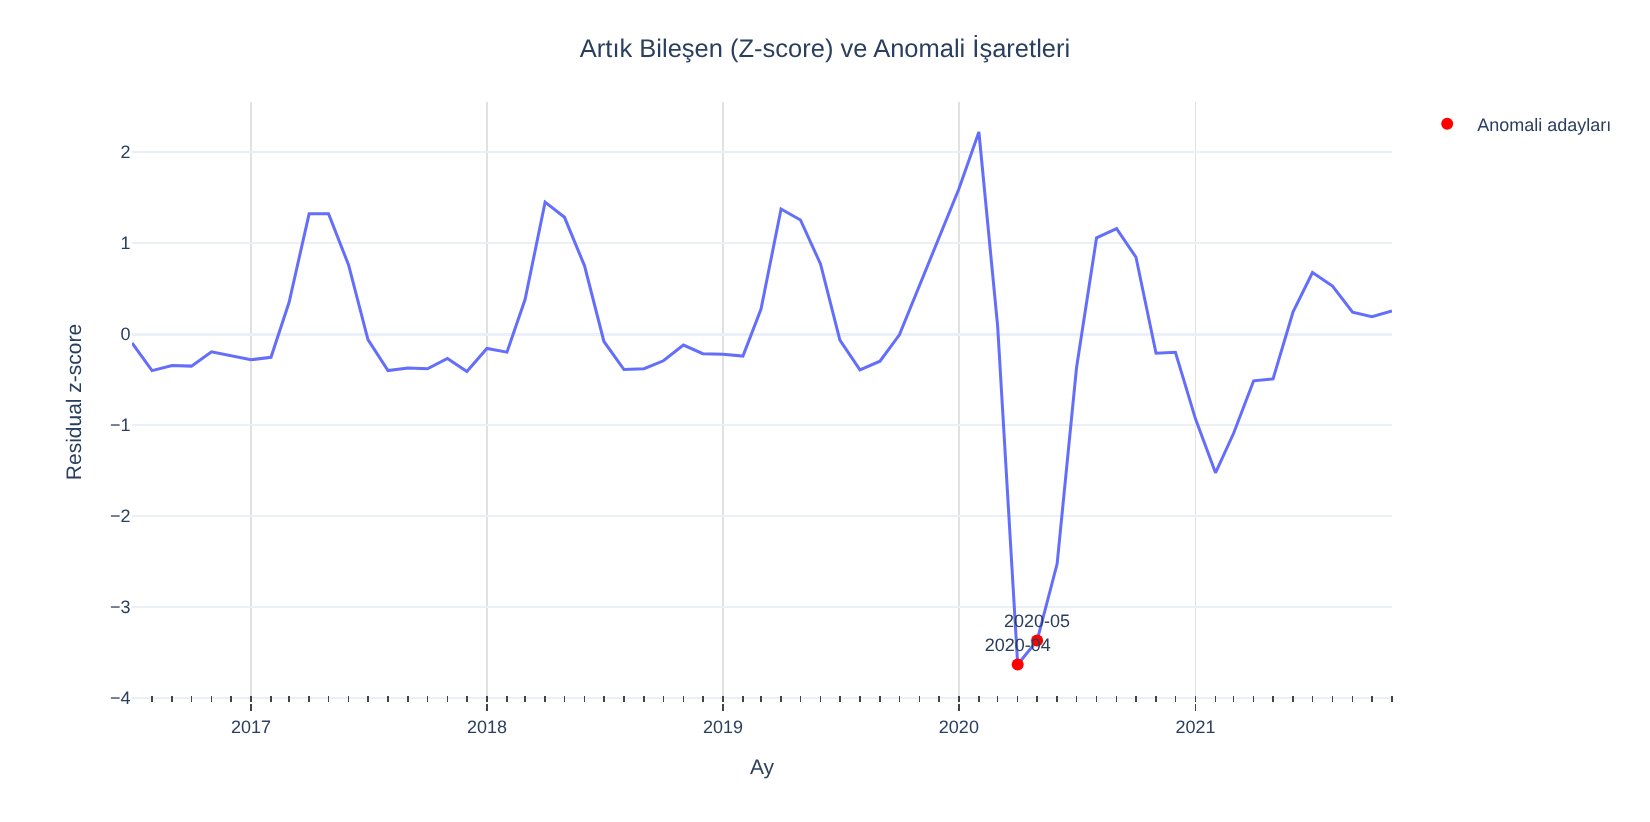

In [12]:
viz_catalog_resid = pd.DataFrame({
    "Özellik": [
        "Grafik Türü",
        "Mark (İşaret)",
        "X Kanalı",
        "Y Kanalı",
        "Renk Kanalı",
        "Zamansal Değişken",
        "Ölçek Türü (X)",
        "Ölçek Türü (Y)",
        "Veri Türü",
        "Rol",
        "Ayırt Edicilik",
        "Amaç",
        "Tasarım Kararı",
        "Etkileşim"
    ],
    "Açıklama": [
        "Zaman serisi (artık bileşen z-skoru)",
        "Çizgi + nokta (anomali işaretleri)",
        "Zaman (yıl = ana tick, ay = minor tick)",
        "Residual z-score",
        "Normal / anomali aylar",
        "month_start",
        "Interval (zaman)",
        "Interval (standartlaştırılmış)",
        "Nicel (Quantitative)",
        "Measure (ölçüm)",
        "Renk ve nokta sembolleri ile anomali vurgusu",
        "Olağan dışı dönemleri tespit etmek",
        "Yıllar referans alınırken ay düzeyindeki şokların tam zamanı mikro tick’ler ile okunur hale getirildi",
        "Hover ve metin anotasyonları"
    ]
})

display(viz_catalog_resid)


res = (
    decomp.resid.dropna()
    - decomp.resid.dropna().mean()
) / decomp.resid.dropna().std()


anoms = res[res.abs() >= 3]


df_res = res.reset_index(name="resid")
df_res["month_label"] = df_res["month_start"].dt.strftime("%Y-%m")

fig = px.line(
    df_res,
    x="month_start",
    y="resid",
    hover_data={"month_label": True},
    labels={
        "month_start": "Ay",
        "resid": "Residual z-score",
        "month_label": "Ay"
    }
)

fig.update_traces(
    hovertemplate=
        "Ay: %{customdata[0]}<br>" +
        "Residual z-score: %{y:.2f}<extra></extra>"
)


fig.add_scatter(
    x=anoms.index,
    y=anoms.values,
    mode="markers+text",
    text=[d.strftime("%Y-%m") for d in anoms.index],
    customdata=[[d.strftime("%Y-%m")] for d in anoms.index],
    hovertemplate=
        "Ay: %{customdata[0]}<br>" +
        "Residual z-score: %{y:.2f}<extra></extra>",
    textposition="top center",
    name="Anomali adayları",
    marker=dict(color="red", size=8)
)


fig.update_layout(template="plotly_white")
fig.update_layout(
    title={
        "text": "Artık Bileşen (Z-score) ve Anomali İşaretleri",
        "x": 0.5,
        "xanchor": "center"
    },
    template="plotly_white"
)

fig.update_xaxes(
    dtick="M12",
    tickformat="%Y",
    ticks="outside",
    showgrid=True,
    gridcolor="rgba(180,180,180,0.4)",

    minor=dict(
        dtick="M1",
        ticks="inside",
        showgrid=False,
        ticklen=4
    )
)

fig.show()

## Havalimanı Koordinatlarının Entegrasyonu ve Mekânsal Eşleme Kalitesi

Bu çalışmanın ilerleyen aşamalarında yapılacak olan coğrafi ağ görselleştirmeleri, mekânsal kırılganlık analizleri ve hub konumlarının harita üzerinde gösterimi için, her bir havalimanının doğru enlem-boylam bilgisine sahip olması gerekmektedir.

Bu nedenle, analizde kullanılan uçuş verisindeki havalimanları, açık kaynaklı OurAirports veritabanı ile eşleştirilmiştir.

Havalimanı koordinatları şu kaynaktan alınmıştır:

OurAirports - airports.csv
https://ourairports.com/data/airports.csv

Bu veri seti her havalimanı için:


*   ICAO kodu (ident)
*   Enlem (latitude_deg)
*   Boylam (longitude_deg)
*   Resmi ad
*   Ülke kodu

bilgilerini içermektedir.

Uçuş verisinde yer alan her bir havalimanı için:

*   APT_ICAO → uçuş verisindeki ICAO kodu
*   ident → OurAirports’taki ICAO karşılığı

olarak kabul edilmiştir.

Her iki veri setinde ICAO kodları standartlaştırıldıktan sonra, aşağıdaki alanlar üzerinden birleştirme yapılmıştır:
*   ICAO kodu
*   Havalimanı adı
*   Ülke bilgisi
*   Toplam uçuş metrikleri

Bu işlem sonucunda, her havalimanı için hem:
*   trafik büyüklüğü
*   hem de coğrafi konum

aynı tabloda bir araya getirilmiştir.

Eşleme işlemi sonrası şu metrik hesaplanmıştır:

Koordinat eşleşme oranı = enlem bilgisi bulunan kayıtların oranı

Bu çalışma için elde edilen sonuç:

Koordinat eşleşme oranı = %99.38

Bu şu anlama gelir:

Analize giren havalimanlarının neredeyse tamamı (%99’dan fazlası), güvenilir coğrafi koordinatlarla başarıyla eşleştirilmiştir.

Yalnızca çok küçük bir kısım (çoğunlukla kapatılmış, askeri veya kodu farklı kullanılan meydanlar) koordinat içermemektedir.

In [13]:
air_url = "https://ourairports.com/data/airports.csv"
air = pd.read_csv(air_url)


air["icao_guess"] = air["ident"].astype(str).str.strip()

air_geo = air[["icao_guess","latitude_deg","longitude_deg","name","iso_country"]].dropna()


geo = (df[["APT_ICAO","APT_NAME","STATE_NAME"] + metrics]
         .rename(columns={"APT_ICAO":"icao"}))

geo = geo.merge(air_geo, left_on="icao", right_on="icao_guess", how="left")

print("Koordinat eşleşme oranı (%):", (geo["latitude_deg"].notna().mean()*100).round(2))


Koordinat eşleşme oranı (%): 99.38


## Soru 2 -  *“Uçuşlar coğrafi olarak nerelerde yoğunlaşıyor?”*

Zamansal analizde Avrupa hava trafiğinin güçlü bir ritme ve kriz dönemlerinde sistemik kırılmalara sahip olduğunu gördük. Ancak bu şokların ağ içinde herkesi eşit biçimde etkileyip etkilemediğini anlayabilmek için önce şu soruya cevap vermemiz gerekir:

Bu trafik coğrafi olarak nasıl dağılmıştır ve hangi havalimanları sistemin merkezinde yer almaktadır?

Bu nedenle ikinci ana analiz ekseni olarak mekânsal boyutu ele alındı.

Alt Sorular

Bu ana soru üç alt soruya ayrılmıştır:


*   Avrupa’da hangi havalimanları sistemsel merkez (hub) rolü üstleniyor?
*   Merkez-çevre yapısı ülkeler arasında nasıl farklılaşıyor?
*   İki veri kaynağı (Network Manager ve havalimanı işletmecisi) merkez havalimanlarında daha mı tutarlı?


Bu sorular, ağın yalnızca “nerede yoğun olduğunu” değil, aynı zamanda nasıl çalıştığını da anlamamızı sağlar.

Bu Soruyu Neden Sorduk?

Hava ulaşım ağları homojen değildir. Büyük hub havalimanları: daha fazla uçuş alır, daha karmaşık trafik yönetircve daha yüksek kontrol ve koordinasyon gerektirir. Dolayısıyla bir krizde ya da kapasite düşüşünde, bu merkezler ağın geri kalanına göre çok daha kritik rol oynar.

Bu nedenle coğrafi yoğunlaşmayı ve operasyonel yapıyı birlikte incelemek gerekmekte.

Bu Aşamada Ne Yapıldı?

Önce, uçuş verisindeki ICAO kodlarını, OurAirports veritabanındaki coğrafi koordinatlarla eşleştirildi:

Her havalimanına enlem ve boylam atandı

Eşleşme oranı %99.38 oldu

Bu, ağın neredeyse tamamının güvenilir biçimde harita üzerine taşınabildiği anlamına gelir.

Ardından her havalimanı için şu metrikleri hesaplandı:

Ortalama toplam uçuş sayısı (avg_tot)

Havalimanı işletmecisinin bildirdiği ortalama uçuş sayısı (avg_apt)

Kaynak uyum oranı = havalimanı kaynağı / Network Manager (yalnızca iki kaynağın da dolu olduğu aylar üzerinden)

Böylece her havalimanı artık hem hacim hem de veri tutarlılığı açısından ölçülebilir hale geldi. Havalimanı işletmecisi verisi olmayan havalimanları karşılaştırılamadığı için haritada yalnızca her iki kaynakta verisi bulunan havalimanları yer almaktadır.

### Etkileşimli Görsel: “Mekânsal Yoğunlaşma: Ortalama Uçuş Hacmi ve Kaynak Uyum Oranı”

Bu haritada:

*   Daire konumu - Havalimanının coğrafi yeri
*   Daire boyutu - Ortalama uçuş hacmi
*   Daire rengi - kaynak uyum oranı (1 = iki kaynak aynı sayıyı veriyor)
*   Siyah metin etiketleri - Ülke merkezleri ve
*   bordo metin etiketleri - en büyük hub’lar

olarak kodlanmıştır.

Grafikten Okunan Sonuçlar

Harita çok net bir merkez-çevre yapısı ortaya koymaktadır:

Sistem çekirdeği Batı ve Orta Avrupa’da yoğunlaşmaktadır

Almanya, Fransa, Benelüks, Birleşik Krallık ve Kuzey İtalya bölgesi:

*   En büyük dairelere
*   En koyu renklere

sahiptir. Yani bu bölge ağın en yoğun çekirdeğidir.

Büyük hub’lar en büyük trafik yükünü taşır

Frankfurt, Paris CDG, Amsterdam, Madrid, Londra gibi havalimanları en büyük dairelerle görünmektedir. Bu merkezlerde kaynak uyum oranı 1'e çok yakındır; yani bildirdikleri sayılar Network Manager kayıtlarıyla neredeyse birebir örtüşür.

İki kaynak genel olarak tutarlıdır

Her iki kaynakta verisi bulunan havalimanlarının yaklaşık %90'ında iki kaynak arasındaki fark %5'in altındadır. Belirgin sapmalar birkaç küçük havalimanında yoğunlaşmaktadır (örneğin Svalbard Longyear).

Çevre ülkeler daha küçük ve daha heterojendir

Doğu Avrupa, Balkanlar ve İskandinavya’da daireler küçülür; bu bölgeler ağın spoke (çevre) kısmını temsil eder.

Soru 2 İçin Mekânsal Sonuç

Bu analiz bize şunu açık biçimde göstermektedir:

Avrupa hava trafiği coğrafi olarak dengeli değildir. Aksine, az sayıda güçlü merkez etrafında yoğunlaşmış bir hub-spoke yapısı vardır.

Üstelik bu merkezler en fazla trafiği taşır ve en düzenli veriyi raporlar; dolayısıyla ağın en kritik düğümleridir.

,Grafik,Mark,X Kanalı,Y Kanalı,Boyut Kanalı,Renk Kanalı,Veri Türü (Konum),Veri Türü (Boyut),Veri Türü (Renk),Nitelik,Rol,Amaç
0,Mekânsal Yoğunluk Haritası,Daire (Circle),Boylam (Longitude),Enlem (Latitude),Ortalama toplam uçuş sayısı,Kaynak uyum oranı (havalimanı / NM),Interval,Ratio,Ratio,Quantitative,Measure,Havalimanlarının mekânsal yoğunluk ve operasyonel yapısının analizi


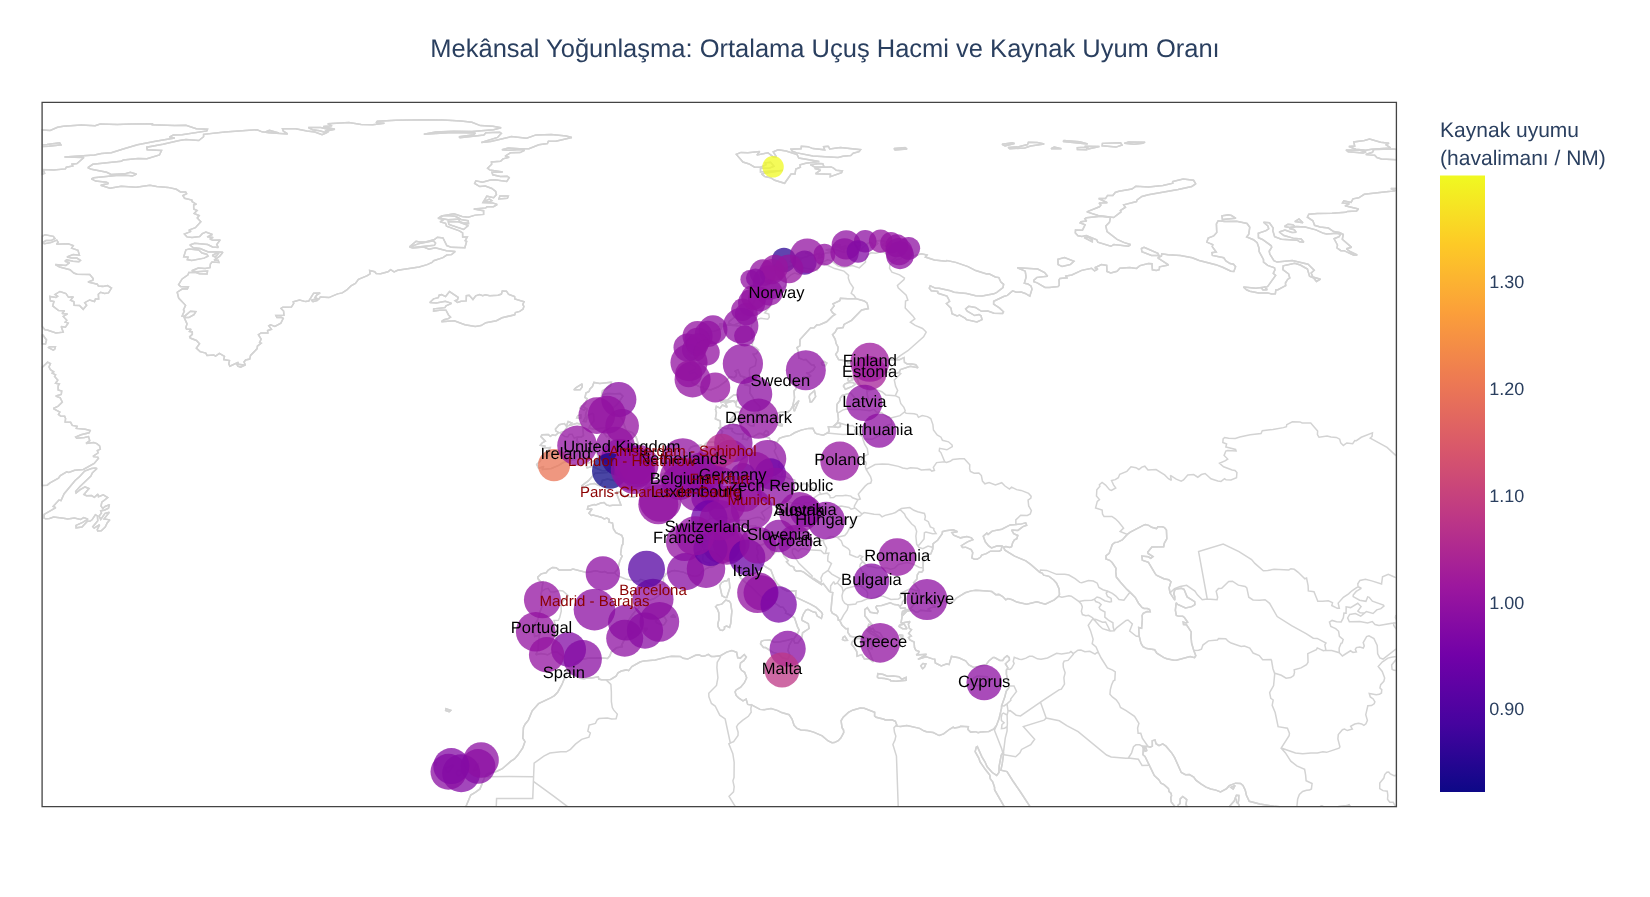

In [14]:
import numpy as np
import pandas as pd
import plotly.express as px


catalog = pd.DataFrame([
    {
        "Grafik": "Mekânsal Yoğunluk Haritası",
        "Mark": "Daire (Circle)",
        "X Kanalı": "Boylam (Longitude)",
        "Y Kanalı": "Enlem (Latitude)",
        "Boyut Kanalı": "Ortalama toplam uçuş sayısı",
        "Renk Kanalı": "Kaynak uyum oranı (havalimanı / NM)",
        "Veri Türü (Konum)": "Interval",
        "Veri Türü (Boyut)": "Ratio",
        "Veri Türü (Renk)": "Ratio",
        "Nitelik": "Quantitative",
        "Rol": "Measure",
        "Amaç": "Havalimanlarının mekânsal yoğunluk ve operasyonel yapısının analizi"
    }
])

display(catalog)


# Kaynak karşılaştırması için yalnızca havalimanı verisinin de bulunduğu aylardaki NM sayısı
geo["FLT_TOT_1_matched"] = geo["FLT_TOT_1"].where(geo["FLT_TOT_IFR_2"].notna())

agg = (
    geo.groupby(
        ["icao", "APT_NAME", "STATE_NAME", "latitude_deg", "longitude_deg"],
        as_index=False
    )
    .agg(
        avg_tot=("FLT_TOT_1", "mean"),
        avg_apt=("FLT_TOT_IFR_2", "mean"),
        avg_nm_matched=("FLT_TOT_1_matched", "mean")
    )
)


agg["source_ratio"] = agg["avg_apt"] / agg["avg_nm_matched"]


agg = agg.dropna(subset=["latitude_deg", "longitude_deg", "avg_tot", "source_ratio"])


agg["size_log"] = np.log1p(agg["avg_tot"])

fig = px.scatter_geo(
    agg,
    lat="latitude_deg",
    lon="longitude_deg",
    size="size_log",
    color="source_ratio",
    hover_name="APT_NAME",
    hover_data={
        "STATE_NAME": True,
        "avg_tot": ":.0f",
        "source_ratio": ":.2f"
    },
    projection="natural earth",
    color_continuous_scale="Plasma"
)

fig.update_traces(
    marker=dict(
        opacity=0.75,
        line=dict(width=0),
        sizemode="area"
    )
)

fig.update_geos(
    fitbounds="locations",
    showcountries=True,
    countrycolor="lightgray",
    showcoastlines=True,
    coastlinecolor="lightgray"
)

fig.update_traces(
    marker=dict(
        opacity=0.75,
        line=dict(width=0),
        sizemode="area"
    )
)

fig.update_geos(
    fitbounds="locations",
    showcountries=True,
    countrycolor="lightgray",
    showcoastlines=True,
    coastlinecolor="lightgray"
)

country_centers = (
    agg.groupby("STATE_NAME", as_index=False)
       .agg(
           lat=("latitude_deg", "mean"),
           lon=("longitude_deg", "mean")
       )
)

fig.add_scattergeo(
    lat=country_centers["lat"],
    lon=country_centers["lon"],
    text=country_centers["STATE_NAME"],
    mode="text",
    textfont=dict(size=11, color="black"),
    showlegend=False
)

fig.update_layout(
    title={
        "text": "Mekânsal Yoğunlaşma: Ortalama Uçuş Hacmi ve Kaynak Uyum Oranı",
        "x": 0.5,
        "xanchor": "center"
    },
    template="plotly_white",
    height=550,
    margin=dict(l=20, r=20, t=60, b=20),
    coloraxis_colorbar=dict(
        title="Kaynak uyumu<br>(havalimanı / NM)",
        tickformat=".2f"
    )
)

big_hubs = agg[agg["avg_tot"] > agg["avg_tot"].quantile(0.95)]

fig.add_scattergeo(
    lat=big_hubs["latitude_deg"],
    lon=big_hubs["longitude_deg"],
    text=big_hubs["APT_NAME"],
    mode="text",
    textposition="top center",
    textfont=dict(size=10, color="darkred"),
    showlegend=False
)

fig.show()


## Soru 2 -  *“Uçuşlar coğrafi olarak nerelerde yoğunlaşıyor?”*
### Alt Soru 3 - *İki veri kaynağı nerede ayrışıyor?*

Havalimanı İşletmecisinin Network Manager'dan Daha Fazla Uçuş Bildirdiği Havalimanları

Bu adımda, kaynak uyum oranı (havalimanı işletmecisi / Network Manager) en yüksek olan 10 havalimanı yatay çubuk grafikle gösterilmiştir. Oranın 1'in üzerinde olması, havalimanı işletmecisinin aynı dönem için Network Manager'dan daha fazla IFR hareketi bildirdiği anlamına gelir.

En büyük farklar Svalbard Longyear (yaklaşık 1,40) ve Cork'ta (yaklaşık 1,20) görülmektedir; listedeki diğer havalimanlarında fark %10'un altındadır. Bu tür farklar; hangi hareketlerin sayıldığına dair tanım farklılıklarından (örneğin eğitim, konumlandırma veya Network Manager sistemine uçuş planıyla yansımayan hareketler), raporlama dönemlerinin örtüşmemesinden ya da kayıt hatalarından kaynaklanabilir. Kesin neden yalnızca bu veriden çıkarılamaz.

Bu bulgu, büyük hub'larda iki kaynağın neredeyse birebir örtüştüğünü, tutarsızlığın ise ağın çevresindeki küçük havalimanlarında yoğunlaştığını göstermektedir. Veri kalitesi açısından bu havalimanları, iki kaynağın birlikte kullanıldığı analizlerde ayrıca kontrol edilmesi gereken noktalardır.


,Özellik,Açıklama
0,Grafik Türü,Yatay çubuk grafik
1,Mark (İşaret),Dikdörtgen (bar)
2,X Kanalı,Kaynak uyum oranı (havalimanı / NM)
3,Y Kanalı,Havalimanı
4,Veri Türü (X),Ratio (oransal)
5,Veri Türü (Y),Kategorik
6,Nitelik,Nicel (quantitative)
7,Rol,Measure (ölçüm)
8,Analiz Düzeyi,Havalimanı bazlı
9,Amaç,Kaynak uyum oranı en yüksek 10 havalimanı


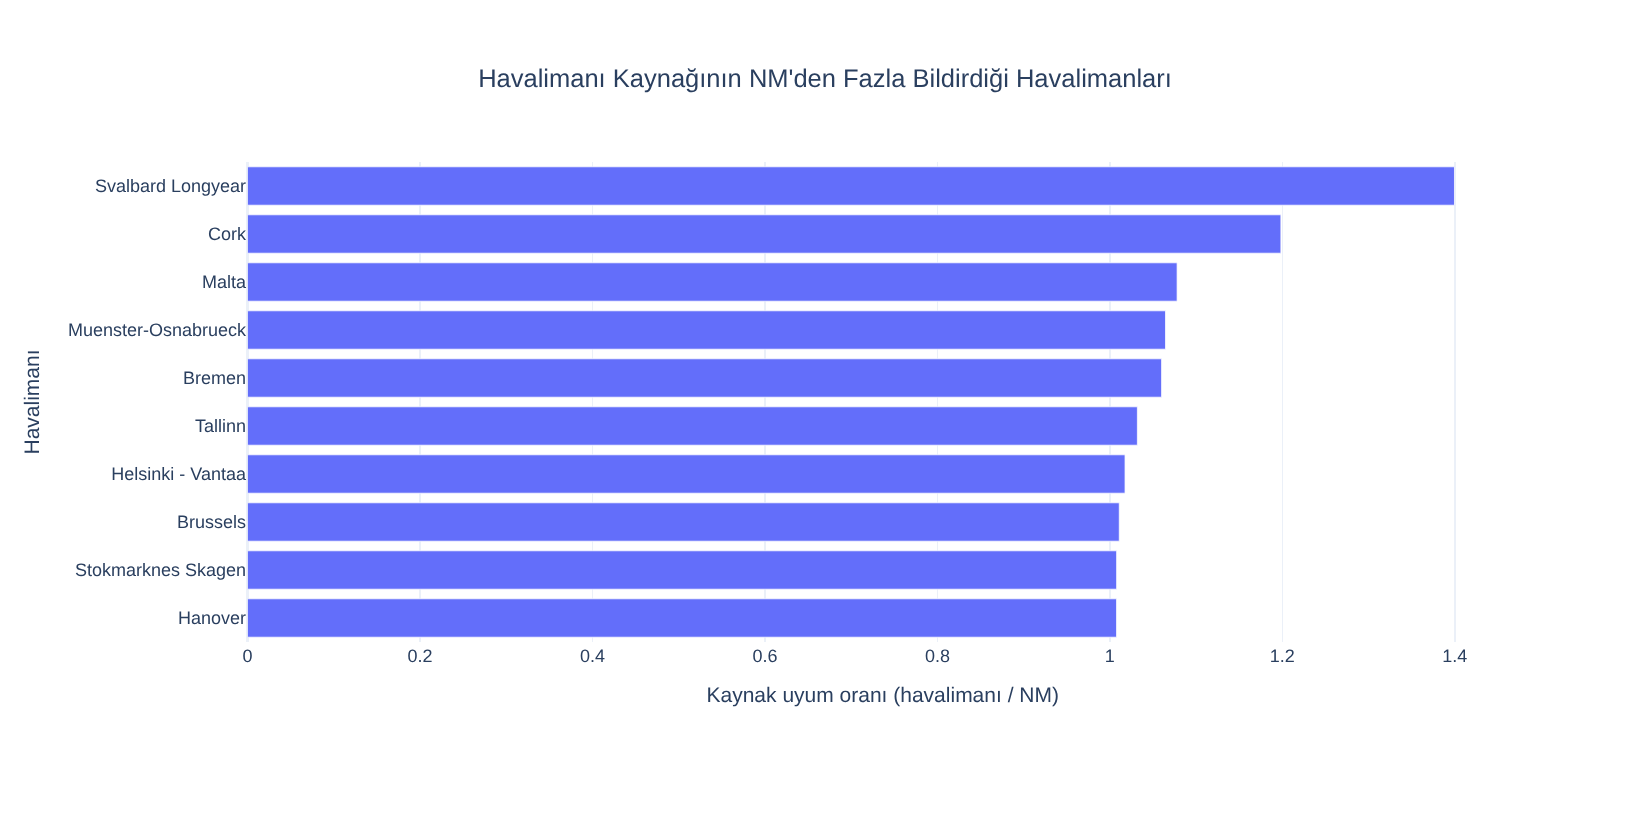

In [15]:
ratio_airport_catalog = pd.DataFrame({
    "Özellik": [
        "Grafik Türü",
        "Mark (İşaret)",
        "X Kanalı",
        "Y Kanalı",
        "Veri Türü (X)",
        "Veri Türü (Y)",
        "Nitelik",
        "Rol",
        "Analiz Düzeyi",
        "Amaç"
    ],
    "Açıklama": [
        "Yatay çubuk grafik",
        "Dikdörtgen (bar)",
        "Kaynak uyum oranı (havalimanı / NM)",
        "Havalimanı",
        "Ratio (oransal)",
        "Kategorik",
        "Nicel (quantitative)",
        "Measure (ölçüm)",
        "Havalimanı bazlı",
        "Kaynak uyum oranı en yüksek 10 havalimanı"
    ]
})

display(ratio_airport_catalog)

high_ratio_airports = (
    agg.sort_values("source_ratio", ascending=False)
       .head(10)
)

fig_high = px.bar(
    high_ratio_airports,
    x="source_ratio",
    y="APT_NAME",
    orientation="h",
    labels={
        "source_ratio": "Kaynak uyum oranı (havalimanı / NM)",
        "APT_NAME": "Havalimanı"
    },
    title="Havalimanı Kaynağının NM'den Fazla Bildirdiği Havalimanları"
)


fig_high.update_yaxes(autorange="reversed")

fig_high.update_layout(
    template="plotly_white",
    height=500,
    title={"x": 0.5, "xanchor": "center"}
)

fig_high.show()


## Havalimanı İşletmecisinin Daha Az Uçuş Bildirdiği Havalimanları

Bu adımda kaynak uyum oranı en düşük olan 10 havalimanı gösterilmiştir. Oranın 1'in altında olması, havalimanı işletmecisinin Network Manager'a kıyasla daha az IFR hareketi bildirdiği anlamına gelir.

Bu grafikteki havalimanlarında oran 0,8 ile 0,95 arasındadır; yani farklar sınırlıdır (en büyük fark Bristol'da, yaklaşık 0,82). Bu sapmalar da büyük ölçüde raporlama kapsamı ve tanım farklarına işaret etmektedir.

Sonuç olarak iki kaynak, verisi bulunan havalimanlarının büyük çoğunluğunda tutarlıdır; anlamlı farklar az sayıda havalimanında görülmektedir. Bu durum, hangi kaynağın hangi amaçla kullanılacağına karar verirken havalimanı bazında kontrol yapılması gerektiğini göstermektedir.


,Özellik,Açıklama
0,Grafik Türü,Yatay çubuk grafik
1,Mark (İşaret),Dikdörtgen (bar)
2,X Kanalı,Kaynak uyum oranı (havalimanı / NM)
3,Y Kanalı,Havalimanı
4,Veri Türü (X),Ratio (oransal)
5,Veri Türü (Y),Kategorik
6,Nitelik,Nicel (quantitative)
7,Rol,Measure (ölçüm)
8,Analiz Düzeyi,Havalimanı bazlı
9,Amaç,Kaynak uyum oranı en düşük havalimanları


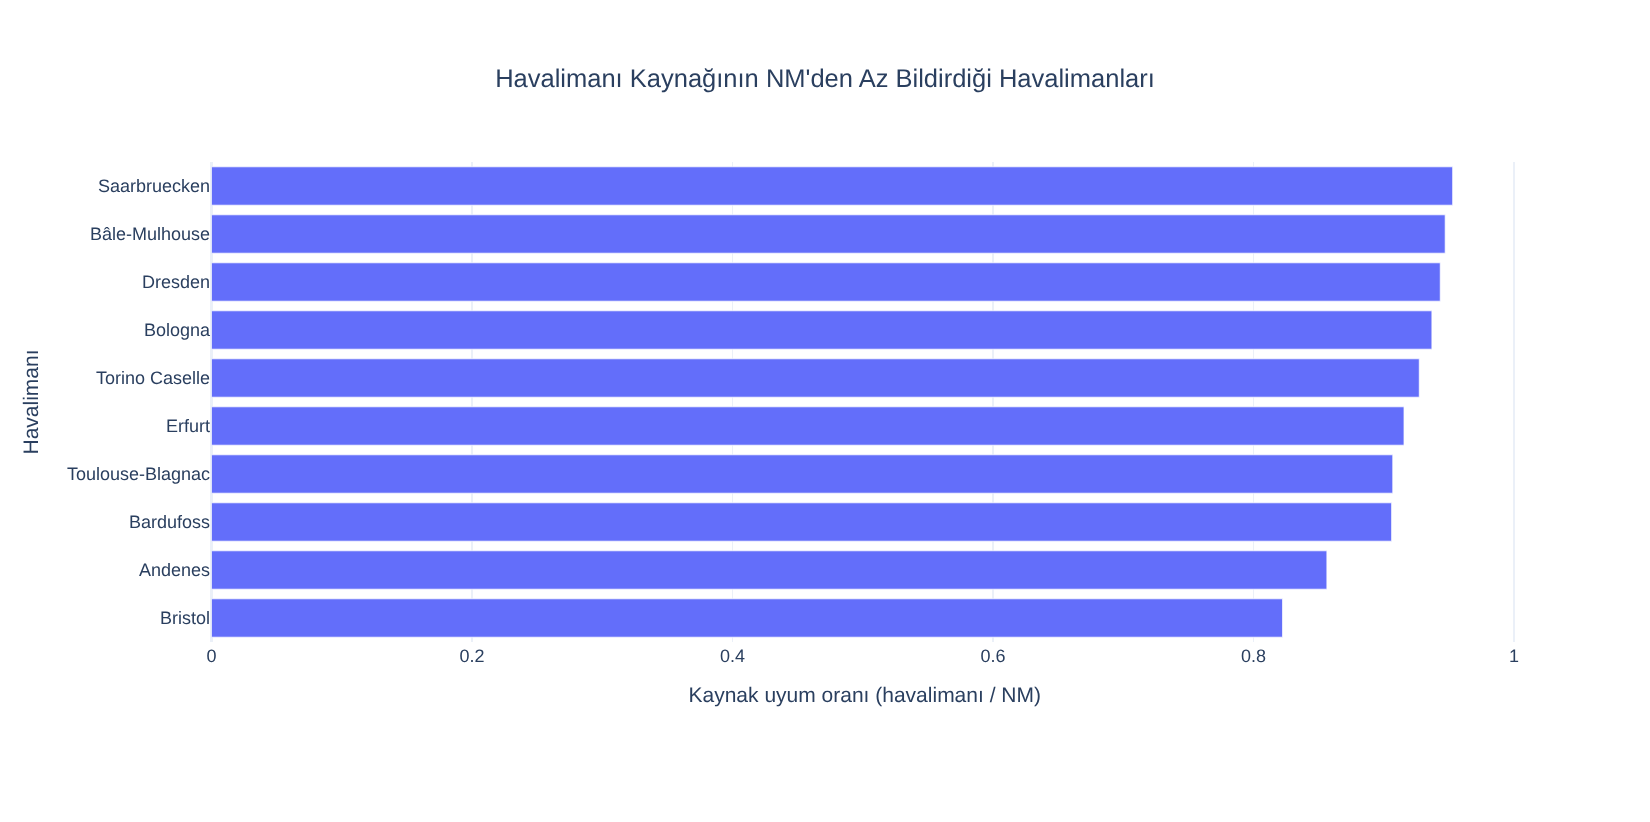

In [16]:
ratio_airport_catalog = pd.DataFrame({
    "Özellik": [
        "Grafik Türü",
        "Mark (İşaret)",
        "X Kanalı",
        "Y Kanalı",
        "Veri Türü (X)",
        "Veri Türü (Y)",
        "Nitelik",
        "Rol",
        "Analiz Düzeyi",
        "Amaç"
    ],
    "Açıklama": [
        "Yatay çubuk grafik",
        "Dikdörtgen (bar)",
        "Kaynak uyum oranı (havalimanı / NM)",
        "Havalimanı",
        "Ratio (oransal)",
        "Kategorik",
        "Nicel (quantitative)",
        "Measure (ölçüm)",
        "Havalimanı bazlı",
        "Kaynak uyum oranı en düşük havalimanları"
    ]
})

display(ratio_airport_catalog)

airport_src = (
    agg
    .loc[agg["avg_tot"] > 0]
    .copy()
    .sort_values("source_ratio")
)

low_ratio_airports = airport_src.head(10)

fig_low = px.bar(
    low_ratio_airports,
    x="source_ratio",
    y="APT_NAME",
    orientation="h",
    labels={
        "source_ratio": "Kaynak uyum oranı (havalimanı / NM)",
        "APT_NAME": "Havalimanı"
    },
    title="Havalimanı Kaynağının NM'den Az Bildirdiği Havalimanları"
)

fig_low.update_layout(
    template="plotly_white",
    height=500,
    title={"x": 0.5, "xanchor": "center"}
)

fig_low.show()




## Soru 3 - *“Zaman ilerledikçe, uçuş trafiğinin coğrafi deseni nasıl evriliyor?”*

Bu aşamada, Avrupa’daki havalimanlarının zaman içinde nasıl bir operasyonel dönüşüm geçirdiğini incelemek amacıyla animasyonlu bir dağılım grafiği kullanılmıştır. Amaç, yalnızca toplam uçuş hacminin zamansal değişimini değil, her bir havalimanının göreli yoğunluğunun aylar boyunca nasıl evrildiğini görsel olarak izleyebilmektir.

Bu analiz, statik grafiklerin sağlayamadığı bir bakış açısı sunar:
Sistem sadece “nerede yoğun” değil, “hangi havalimanı ne zaman yoğunlaşıyor?” sorusuna yanıt verir.

Grafikte:
Havalimanları, zamansal ve operasyonel bir uzay içinde konumlandırılmıştır.

*   Her nokta bir havalimanını temsil eder
*   X ekseni: Ay (zaman)
*   Y ekseni: O ayda gerçekleşen toplam uçuş sayısı
*   Nokta boyutu: Uçuş yoğunluğu
*   Nokta rengi: Kaynak uyum oranı (yalnızca havalimanı işletmecisi verisi bulunan havalimanları gösterilmiştir)

Animasyon: Aylar ilerledikçe her havalimanının bu uzaydaki konumunun nasıl değiştiğini gösterir.

Bu yapı sayesinde her havalimanının yıl içindeki “operasyonel hareketi” izlenebilmektedir.

Bu görselle neyi inceledik?

Animasyon ilerledikçe aşağıdaki örüntüler net biçimde ortaya çıkmaktadır:


*   Bazı havalimanları yıl boyunca yüksek uçuş hacmiyle sabit kalmaktadır. Bunlar ağın istikrarlı merkezleri (hub’ları)dır.
*   Bazı havalimanları yaz aylarında belirgin biçimde büyüyüp kış aylarında küçülmektedir. Bunlar daha çok mevsimsel ve turistik karakterli düğümlerdir.
*  Kaynak uyum oranı büyük havalimanlarında zaman içinde 1 civarında sabit kalırken, bazı küçük havalimanlarında aydan aya dalgalanmaktadır.

Bu durum, trafik yoğunluğunun yalnızca havalimanının konumuna değil, aynı zamanda zamansal bağlama da bağlı olduğunu göstermektedir.

### Soru 3 için çıkarım

Bu animasyonlu grafik şunu açık biçimde ortaya koymaktadır:

Avrupa hava ulaşım ağı, hem zaman içinde dalgalanan, hem de bu dalgalanmayı coğrafi olarak yeniden dağıtan canlı bir sistemdir.

Yoğunluk yalnızca artıp azalmaz,
kıtaya yayılır, çekilir ve yeniden merkezlenir.

Bu, ağın neden bazı düğümlerde (hub’larda) daha kırılgan olduğunu anlamak için kritik bir adımdır.

,Özellik,Açıklama
0,Grafik Türü,Animasyonlu dağılım grafiği (scatter)
1,Mark (İşaret),Üçgen (triangle-up)
2,X Kanalı,Zaman (ay)
3,Y Kanalı,Toplam uçuş sayısı
4,Boyut Kanalı,Toplam uçuş sayısı (ölçeklenmiş)
5,Renk Kanalı,Kaynak uyum oranı (havalimanı / NM)
6,Animasyon Kanalı,Ay (month_start)
7,Animasyon Gruplama,Havalimanı (APT_ICAO)
8,Veri Türü (X),Interval (zamansal)
9,Veri Türü (Y),Ratio (sayım)


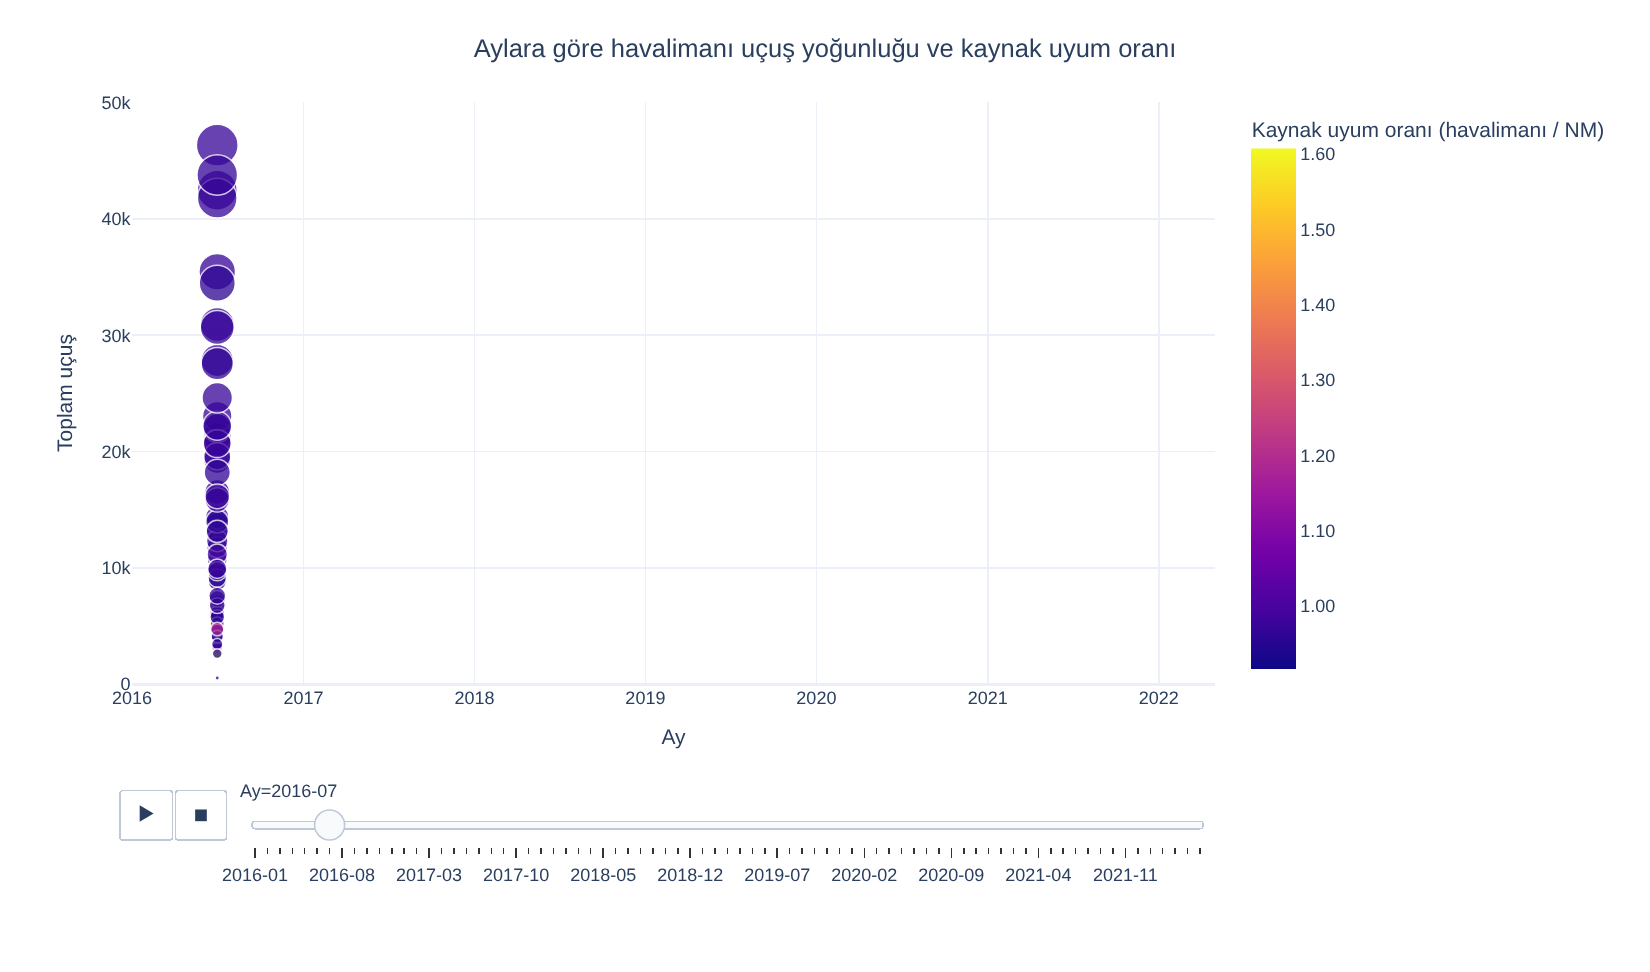

In [17]:
import pandas as pd
import numpy as np
import plotly.express as px

URL = "https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/data/2022/2022-07-12/flights.csv"
df = pd.read_csv(URL)

viz_catalog_temporal = pd.DataFrame({
    "Özellik": [
        "Grafik Türü",
        "Mark (İşaret)",
        "X Kanalı",
        "Y Kanalı",
        "Boyut Kanalı",
        "Renk Kanalı",
        "Animasyon Kanalı",
        "Animasyon Gruplama",
        "Veri Türü (X)",
        "Veri Türü (Y)",
        "Veri Türü (Boyut)",
        "Veri Türü (Renk)",
        "Nitelik",
        "Rol",
        "Analiz Düzeyi",
        "Amaç",
        "Etkileşim"
    ],
    "Açıklama": [
        "Animasyonlu dağılım grafiği (scatter)",
        "Üçgen (triangle-up)",
        "Zaman (ay)",
        "Toplam uçuş sayısı",
        "Toplam uçuş sayısı (ölçeklenmiş)",
        "Kaynak uyum oranı (havalimanı / NM)",
        "Ay (month_start)",
        "Havalimanı (APT_ICAO)",
        "Interval (zamansal)",
        "Ratio (sayım)",
        "Ratio (sayım)",
        "Ratio (oransal)",
        "Nicel (quantitative)",
        "Measure (ölçüm)",
        "Havalimanı bazlı",
        "Uçuş yoğunluğunun ve iki kaynağın uyumunun zaman içindeki değişimini incelemek",
        "Animasyon, hover ile ayrıntı okuma"
    ]
})

display(viz_catalog_temporal)


df["FLT_DATE"] = pd.to_datetime(df["FLT_DATE"], errors="coerce")
df["month_start"] = df["FLT_DATE"].dt.to_period("M").dt.to_timestamp()

air_url = "https://ourairports.com/data/airports.csv"
air = pd.read_csv(air_url)

air["icao_guess"] = air["ident"].astype(str).str.strip()

air_geo = air[
    ["icao_guess", "latitude_deg", "longitude_deg"]
].dropna()

geo_time = (
    df.merge(
        air_geo,
        left_on="APT_ICAO",
        right_on="icao_guess",
        how="left"
    )
)

geo_time = geo_time.dropna(
    subset=["latitude_deg", "longitude_deg", "month_start"]
)

frame = (
    geo_time
    .groupby(
        [
            "month_start",
            "APT_ICAO",
            "APT_NAME",
            "STATE_NAME",
            "latitude_deg",
            "longitude_deg"
        ],
        as_index=False
    )
    .agg(
        tot=("FLT_TOT_1", "sum"),
        apt=("FLT_TOT_IFR_2", lambda s: s.sum(min_count=1))
    )
)

frame["source_ratio"] = frame["apt"] / frame["tot"]  # havalimanı verisi olmayan aylar NaN kalır

frame = frame.replace([np.inf, -np.inf], np.nan)
frame = frame.dropna(subset=["tot", "source_ratio"])

fig = px.scatter(
    frame,
    x="month_start",
    y="tot",
    size="tot",
    color="source_ratio",
    animation_frame=frame["month_start"].dt.strftime("%Y-%m"),
    animation_group="APT_ICAO",
    hover_name="APT_NAME",
    hover_data={
        "STATE_NAME": True,
        "tot": ":.0f",
        "source_ratio": ":.2f"
    },
    labels={
        "month_start": "Ay",
        "tot": "Toplam uçuş",
        "source_ratio": "Kaynak uyumu"
    }
)

fig.update_traces(
    marker=dict(symbol="triangle-up", opacity=0.75)
)

fig.update_layout(
    template="plotly_white",
    height=600,
    xaxis_title="Ay",
    yaxis_title="Toplam uçuş",
    title={
        "text": "Aylara göre havalimanı uçuş yoğunluğu ve kaynak uyum oranı",
        "x": 0.5,
        "xanchor": "center"
    },
    coloraxis_colorbar=dict(
        title="Kaynak uyum oranı (havalimanı / NM)",
        tickformat=".2f"
    )
)

fig.update_xaxes(
    range=[frame["month_start"].min(), frame["month_start"].max()]
)

fig.update_yaxes(
    range=[0, frame["tot"].max() * 1.05]
)

fig.show()
